# Nebulae

Fünf Nebel, jeweils mit echten Daten: die Dunkelwolke um ρ Ophiuchi, der Orionnebel vom Röntgen- bis zum Radiobereich, die H-II-Regionen der Galaxie M 101 mit Temperatur und Sauerstoff, Planetarische Nebel als Thermometer, Uhren und Entfernungsmesser bis M 31 und die Ausdehnung des Krebsnebels seit 1054. Die Daten kommen aus SkyView, Gaia, 2MASS, SDSS, Pan-STARRS, VizieR, den Palomar-Platten, Planck und Jodrell Bank; Downloads landen in `data/nebulae/`. Der Code steht in [`code/nebulae/`](https://github.com/deltorobarba/science/tree/main/code/nebulae), ein Modul je Nebel (`ophiuchus.py`, `orion.py`, `hii.py`, `planetary.py`, `crab.py`, dazu `nebdata.py` für den Cache); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Die fünf Teile folgen dem Leben der Sterne, von der Wolke, in der sie entstehen, bis zu dem, was sie am Ende abstoßen. Bei jedem Nebel stellt sich dieselbe Frage: Was verrät sein Licht über Entfernung, Temperatur, Dichte und Masse?

- **Schritte 1 bis 14, ρ Ophiuchi:** Eine Dunkelwolke, in der Sterne entstehen, auf drei Wegen kartiert: mit den Farben der Sterne dahinter, mit der Wärmestrahlung des Staubs und mit der Entfernung, ab der Gaia-Sterne gerötet sind.
- **Schritte 15 bis 26, Orion:** Ein junger, massereicher Stern ionisiert die Oberfläche seiner Wolke. Bilder vom Röntgen- bis zum Radiobereich ergeben Entfernung, ionisierende Leistung, Größe und Staubtemperatur des Nebels.
- **Schritte 27 bis 40, H-II-Regionen in M 101:** Viele solche Gaswolken in einer anderen Galaxie. Schwache Linien geben die Temperatur des Gases, die Temperatur den Sauerstoff, und der Sauerstoff nimmt nach außen ab.
- **Schritte 41 bis 55, Planetarische Nebel:** Die abgestoßene Hülle eines sterbenden Sterns bis etwa acht Sonnenmassen. Der Nebel zählt die Photonen seines Zentralsterns, misst dessen Alter und dient als Entfernungsmesser bis M 31.
- **Schritte 56 bis 70, Krebsnebel:** Der Rest der Supernova von 1054. Drei Bilder aus 60 Jahren zeigen, dass der Nebel schneller wächst, als er sollte; der Pulsar in der Mitte liefert die Energie dafür.

Die gemeinsame Lehre: Atomphysik und Geometrie reichen weit. Ein festes Linienverhältnis gibt Rötung und Temperatur, gezählte Photonen die Leistung eines Sterns, den man kaum sieht, und Bewegungen am Himmel zusammen mit Parallaxen oder Geschwindigkeiten im Spektrum die Entfernung.

In [1]:
import sys
import subprocess
import urllib.request
import importlib.util
from pathlib import Path

CODE = Path.cwd() / "code" / "nebulae"
if "google.colab" in sys.modules:                            # in Colab: Paket installieren, Code aus dem Repository holen
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery"], check=True)
    if not CODE.exists():
        CODE.mkdir(parents=True)
        for f in ["nebdata.py", "ophiuchus.py", "orion.py", "hii.py", "planetary.py", "crab.py"]:
            urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/nebulae/{f}", CODE / f)
elif importlib.util.find_spec("astroquery") is None:
    raise ImportError("Es fehlt astroquery; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import ophiuchus, orion, hii, planetary, crab

**1. ρ Ophiuchi: eine Dunkelwolke auf drei Wegen**

1784 stieß Herschel im Skorpion auf eine Stelle ohne Sterne und hielt sie für ein Loch im Himmel. Erst Barnard und Wolf zeigten, dass es Wolken sind, die das Licht dahinter verschlucken, und Trumpler 1930, dass der Staub die ganze Milchstraße durchzieht. Die Wolke um ρ Ophiuchi ist eine der nächsten; in ihrem dichten Kern L1688 sitzen einige hundert junge Sterne, die man nur im Infraroten sieht. Man kann sie auf drei Wegen kartieren: mit den Farben der Sterne dahinter (2MASS), mit der Wärmestrahlung des Staubs (IRAS, Planck) und mit der Entfernung, ab der Gaia-Sterne gerötet sind.

Geladen werden 102 443 Sterne aus 2MASS im Feld und 51 321 in einem Kontrollfeld mit wenig Staub, 15 340 Gaia-Sterne mit guter Parallaxe und Extinktion, Bilder in sechs Bändern vom Blauen bis 850 µm und ein Rechengitter mit 3′ pro Pixel. Dazu die Umrechnungen der Farben in Extinktion: A_V = 15.87 · E(H−K) und 9.35 · E(J−H).

In [2]:
ophiuchus.load()

2MASS: 102443 Quellen im Feld, 51321 im Kontrollfeld (E(B−V) = 0.140 nach Schlafly & Finkbeiner)
Gaia DR3 mit Parallaxe S/N > 5 und A_G: 15340 Sterne
Bilder: DSS2 Blue 200², DSS2 Red 200², WISE 12 200², IRIS100 200², Planck 857 I 200², Planck 353 I 200² | Rechengitter 60² zu 3′
Medianwerte im Feld [MJy/sr]: IRIS100 118.4, Planck 857 I 57.7, Planck 545 I 17.8, Planck 353 I 4.9
Rechengitter: Mitte (247.0, -24.2), 3.0′ pro Pixel; A_V/E(H−K) = 15.87, A_V/E(J−H) = 9.35, E(J−H)/E(H−K) = 1.70


**2. Die Wolke in sechs Bändern**

Dasselbe Feld von 3° × 3° in sechs Bändern: Fotoplatten in Blau und Rot, WISE bei 12 µm, die Wärmestrahlung des Staubs bei 100, 350 und 850 µm. Markiert sind die hellen B-Sterne ρ Oph, HD 147889 und 22 Sco.

Im Blauen ist die Wolke ein dunkles Band mit fehlenden Sternen, um die hellen Sterne leuchten blaue Reflexionsnebel (Staub streut blaues Licht stärker). Bei 12 µm leuchtet nur Staub, den ein heißer Stern direkt bestrahlt. Im fernen Infrarot ist die Wolke hell statt dunkel: Bei 100 µm liegt das Maximum am warmen Staub um HD 147889, bei 850 µm im kalten, dichten Kern daneben, wo die meiste Masse ist.

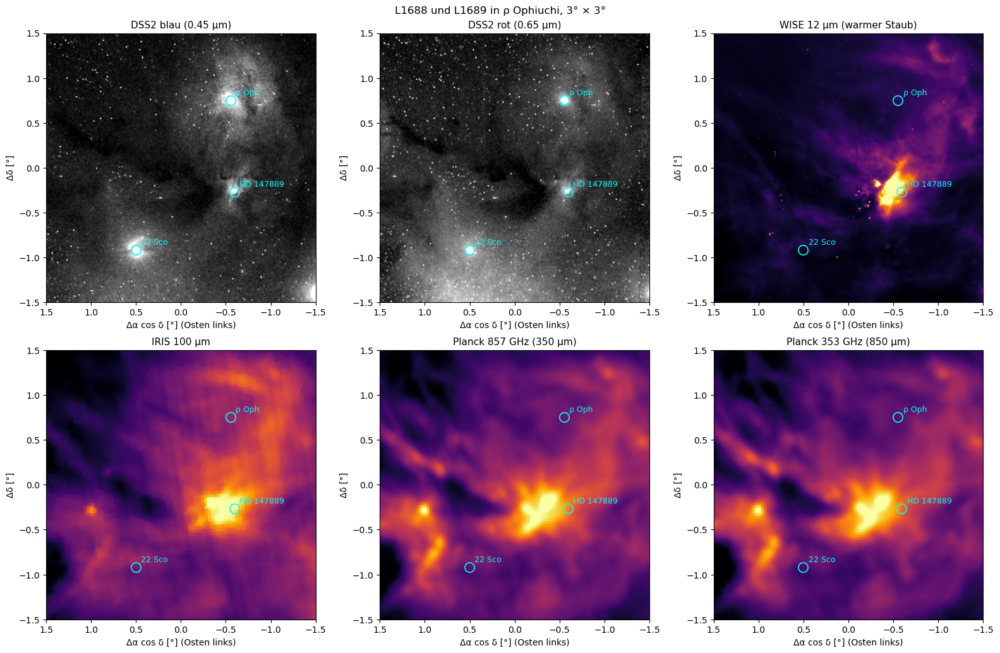

DSS2 Blue     : Median   3935.000, 99.5. Perzentil  11380.015
DSS2 Red      : Median   4494.000, 99.5. Perzentil   9822.080
WISE 12       : Median    924.137, 99.5. Perzentil   2425.351
IRIS100       : Median    118.321, 99.5. Perzentil   1773.666
Planck 857 I  : Median     57.783, 99.5. Perzentil    529.467
Planck 353 I  : Median      0.017, 99.5. Perzentil      0.166


In [3]:
ophiuchus.bands()

**3. Sterne in Richtung der Wolke**

Gezählt werden die Sterne aus 2MASS und aus Gaia pro Pixel von 3′ und mit der Helligkeit bei 857 GHz verglichen.

Je mehr Staub strahlt, desto weniger Sterne kommen durch. In den 5 % hellsten Planck-Pixeln sieht 2MASS noch 4.9 Sterne pro Pixel, Gaia nur 0.3, weil die Extinktion im Optischen zehnmal größer ist als im Infraroten. 2MASS taugt deshalb für die Extinktionskarte, Gaia nur für den Rand der Wolke und die Sterne davor.

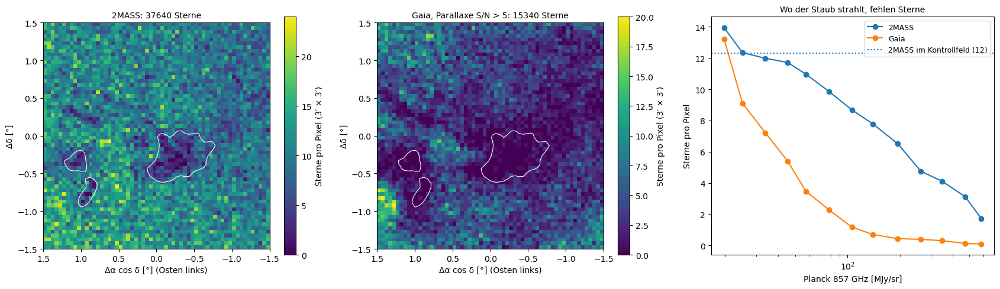

2MASS nach Qualitätsschnitt: 37640 von 102443 im Feld, 15489 von 51321 im Kontrollfeld; mit J: 96%
Sterne pro Pixel: 2MASS Median 10 (Kontrollfeld 12.3), leere Pixel 10; Gaia Median 3, leere Pixel 460
In den 5 % hellsten Planck-Pixeln: 2MASS 4.9, Gaia 0.3 Sterne pro Pixel


In [4]:
ophiuchus.stars()

**4. Farben ohne und mit Staub**

Im Kontrollfeld zeigen die Sterne ihre Eigenfarben; im Feld der Wolke sind dieselben Sterne entlang des Rötungsvektors verschoben, und die Länge der Verschiebung ist die Extinktion.

Ohne Staub liegen die Sterne bei H−K ≈ 0.09 und J−H ≈ 0.45. In der Wolke ist dieselbe Sternwolke nach rechts oben gezogen, bis J−H über 2.5, mit der Steigung 1.70. Die Eigenfarben streuen so stark, dass ein einzelner Stern A_V nur auf gut 1 mag genau gibt; erst der Median vieler Sterne macht die Karte genau.

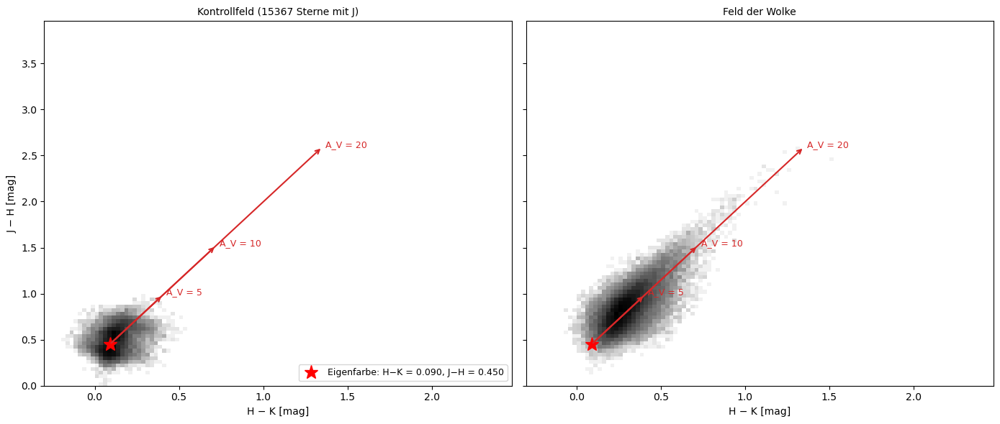

Kontrollfeld: H−K Median 0.117, J−H Median 0.497; abzüglich A_V = 0.43: H−K₀ = 0.090 ± 0.073, J−H₀ = 0.450 ± 0.156 (Streuung)
Streuung in A_V pro Stern aus der Eigenfarbe: H−K 1.15 mag, J−H 1.45 mag


In [5]:
ophiuchus.colors()

**5. Die Extinktionskarte**

Jeder Stern gibt aus H−K und J−H zwei Schätzungen der Extinktion, gewichtet gemittelt; pro Pixel zählt der Median aller Sterne, wenn es mindestens drei sind. Daneben der Vergleich mit Planck bei 857 GHz.

Im Median ist A_V = 3.5 mag, im Kern von L1688 über 20 mag, bis 43.5 mag. Im dichtesten Kern bleiben Pixel ohne Wert, weil zu wenige Sterne durchkommen. Mit Planck korreliert die Karte mit 0.91 (Rang): Staub, der verdeckt, und Staub, der strahlt, sind derselbe. 22 mag im Optischen heißen 10⁹-fach weniger Licht, im Band K nur 2.5 mag.

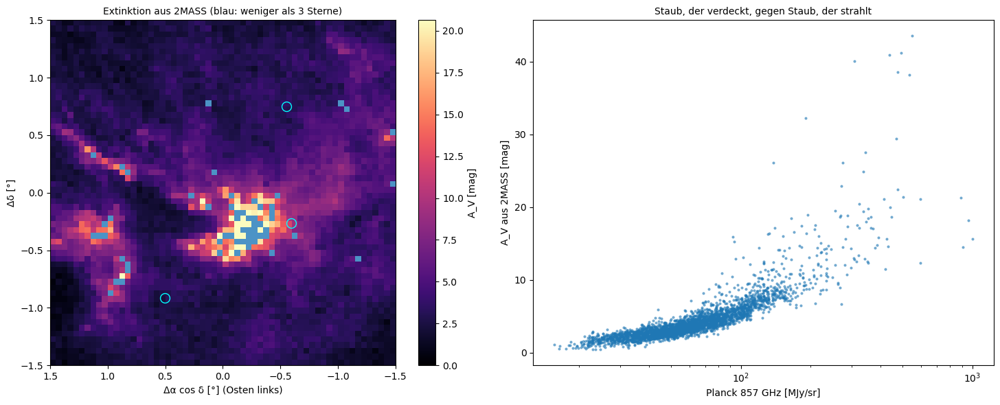

37640 Sterne, A_V pro Stern Median 3.47, Fehler pro Stern Median 1.08 mag
Karte: 3542 von 3600 Pixeln mit ≥ 3 Sternen; A_V Median 3.50, 95. Perzentil 9.2, Maximum 43.5 mag; Rangkorrelation mit Planck 857 0.91
Leere Pixel liegen bei Planck 857 im Median bei 279 MJy/sr (Feld 58)


In [6]:
ophiuchus.extinction_map()

**6. Rötung gegen Entfernung**

Gaia schätzt für jeden Stern die Extinktion A_G aus seinem Spektrum. Die Sterne werden geteilt in solche auf der Wolke und solche daneben, und A_G wird gegen die Entfernung aufgetragen.

Bis 130 pc haben auch die Sterne auf der Wolke fast keine Extinktion; zwischen 130 und 140 pc steigt sie wie an einer senkrechten Wand auf 3 bis 6 mag. Daneben steigt A_G nur auf 1.1 bis 1.4 mag. Hinter der Wolke sieht Gaia nur die Sterne, die noch hell genug sind; die stärker geröteten fehlen, deshalb ist A_G dort kleiner als die Karte erwarten lässt.

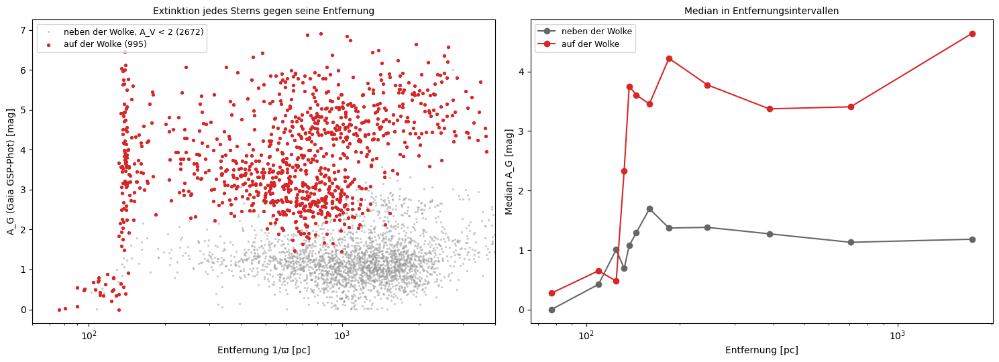

             auf der Wolke (Zahl: A_G) daneben (Zahl: A_G)
d                                                         
(0, 100]                       6: 0.28             1: 0.00
(100, 120]                    10: 0.65             5: 0.42
(120, 130]                     6: 0.48             1: 1.01
(130, 135]                    14: 2.33             1: 0.69
(135, 140]                    43: 3.75             5: 1.07
(140, 150]                    34: 3.60             3: 1.29
(150, 170]                    19: 3.46             5: 1.69
(170, 200]                     9: 4.22             6: 1.37
(200, 300]                    53: 3.77            40: 1.38
(300, 500]                   128: 3.37           158: 1.27
(500, 1000]                  426: 3.41           736: 1.13
(1000, 3000]                 231: 4.64          1604: 1.18


In [7]:
ophiuchus.reddening_distance()

**7. Wie warm ist der Staub?**

In jedem Pixel wird ein modifizierter Schwarzkörper an vier Bänder (100 µm und Planck 857, 545, 353 GHz) angepasst, mit Temperatur, optischer Tiefe und Spektralindex β. Dazu drei Beispiel-Spektren.

Im Median ist der Staub 20.8 K warm, mit β = 1.56. Die dichtesten Pixel haben 18.3 K, der Rest 20.9 K: Dichter Staub ist kälter, weil das Sternlicht nicht eindringt. Warm sind die Umgebung von HD 147889 (bis 36.6 K), ein Bogen um ρ Oph und die Südwestecke, vermutlich von σ Sco knapp außerhalb des Feldes geheizt.

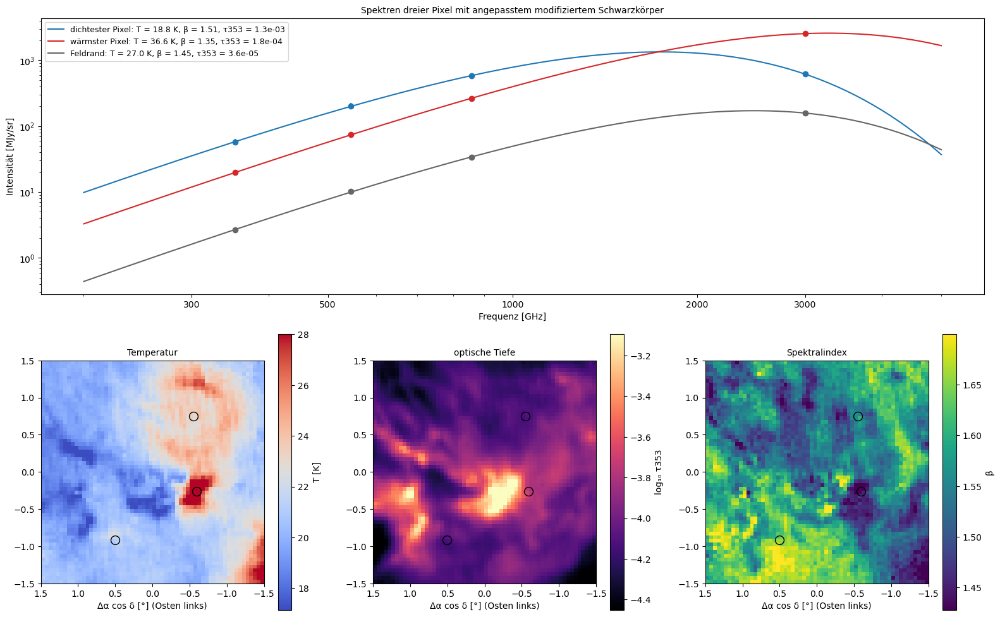

T: Median 20.8 K (5 % bis 95 %: 18.3 bis 24.8), β: Median 1.56 (1.46 bis 1.67); mit β = 1.6: T Median 20.7 K
In den 5 % dichtesten Pixeln: T 18.3 K, sonst 20.9 K; Rangkorrelation T–β -0.25
dichtester Pixel: Δ = (-0.23°, -0.32°), T = 18.8 K, β = 1.51, τ353 = 1.31e-03
wärmster Pixel  : Δ = (-0.58°, -0.22°), T = 36.6 K, β = 1.35, τ353 = 1.80e-04
Feldrand        : Δ = (-1.34°, -1.32°), T = 27.0 K, β = 1.45, τ353 = 3.62e-05


In [8]:
ophiuchus.dust_temperature()

**8. Ein Stern heizt den Staub**

HD 147889 ist ein B2-Stern am Rand von L1688. Seine Heizleistung sollte wie 1/r² fallen, und weil Staub mit T^(4+β) abstrahlt, fällt die Temperatur viel langsamer. Das Modell: gleichmäßige Heizung durch das Licht der Milchstraße plus der Stern.

Die Temperatur fällt von 28.5 K innerhalb von 3′ auf den Hintergrund von 20.9 K jenseits von 30′. Der Beitrag des Sterns fällt mit r^(−2.10 ± 0.13), wie das Abstandsgesetz verlangt. Bis 0.49 pc heizt der Stern stärker als die übrige Milchstraße. Zehnmal weiter heißt hundertmal weniger Heizung, aber nur 2.3-mal weniger Temperatur.

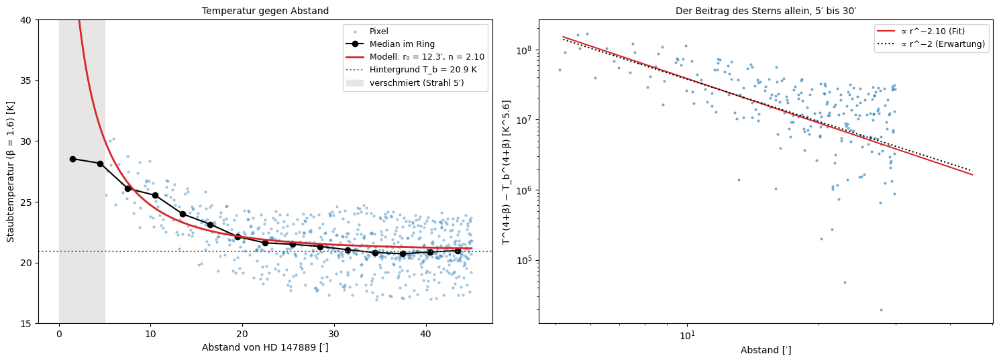

T_b = 20.93 K (Ring 30′ bis 40′); Fit 5′ bis 30′: r₀ = 12.3 ± 0.4′ (0.49 pc), n = 2.10 ± 0.13 (erwartet 2); Gerade im log-log-Bild: Steigung -1.77
Ringmediane: 0–3′ 28.5 K, 9–12′ 25.5 K, 18–21′ 22.1 K, 30–33′ 21.0 K; wärmster Pixel 31.3 K in 2.7′ Abstand


In [9]:
ophiuchus.heating()

**9. Die Entfernung aus dem Sprung**

Ein Modell mit einer dünnen Staubschicht in der Entfernung d: Sterne davor haben wenig Extinktion, Sterne dahinter viel, und welcher Stern wo liegt, folgt mit Wahrscheinlichkeit aus seiner Parallaxe. Für jedes d werden die übrigen Größen optimiert (Profil-Likelihood).

Die Likelihood hat ein scharfes Minimum bei 131.5 ± 1.0 pc: Die Parallaxen sind auf etwa 1 % genau, und der nächste stark gerötete Stern steht bei 131.4 pc. Davor ist A_G = 0.48 mag, dahinter 3.86 mag. Das ist die Vorderkante des Staubs, 6 pc vor den jungen Sternen, die Radio-Interferometrie (VLBI) in 137.3 pc misst.

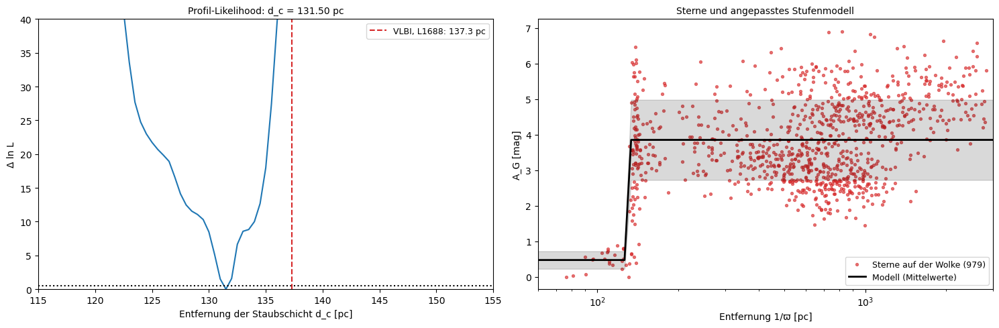

979 Sterne: d_c = 131.50 pc (Profil 1σ: 131.50 bis 131.50, Bootstrap ± 0.95 pc)
davor A_G = 0.48 ± 0.25, dahinter 3.86 ± 1.13 mag, Fremdanteil 0.0%
Sterne vor der Schicht: 25; nächster geröteter Stern (A_G > 2): 131.4 pc


In [10]:
ophiuchus.distance_jump()

**10. Das Extinktionsgesetz im Infraroten**

Für alle gut geröteten Sterne mit J, H und K wird eine Gerade durch J−H gegen H−K gelegt. Beide Achsen haben verschieden große Fehler; die Deming-Regression berücksichtigt das. Junge Sterne mit eigenem Infrarotexzess werden mit einem robusten Schnitt entfernt.

Aus 21 268 Sternen folgt E(J−H)/E(H−K) = 1.653 ± 0.011, 3 % unter dem Standardwert 1.70, vermutlich zum Teil wegen des anderen Filtersystems. Eine ungewichtete Gerade gäbe 1.99, weil sie die größere Streuung in J−H als Steigung liest. Die 408 entfernten Sterne liegen fast alle unter der Geraden: junge Sterne mit Scheibe.

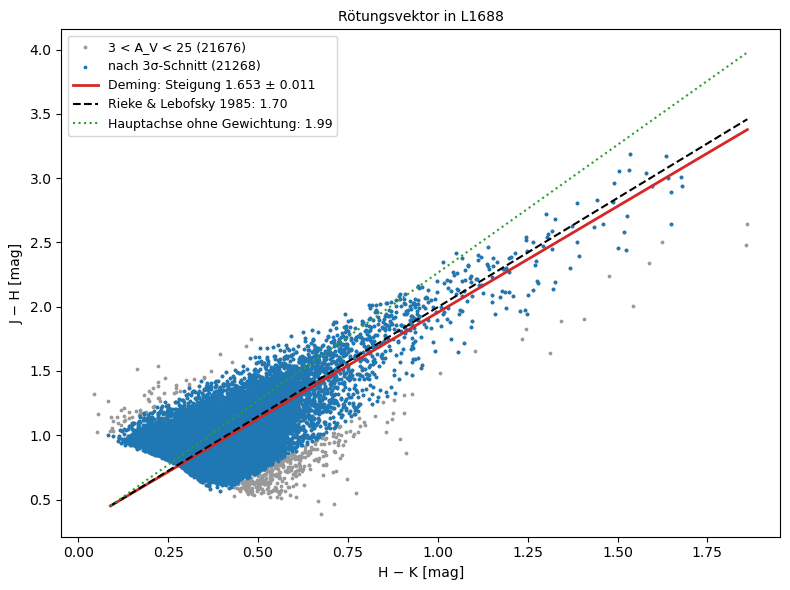

Varianzverhältnis der Fehler δ = 3.12; erster Fit 1.604, nach Schnitt (21268 von 21676) 1.653 ± 0.011; Hauptachse ohne Gewichtung 1.992; Rieke & Lebofsky 1.698
Entfernt (vor allem Infrarotexzess): 408 Sterne, davon unter der Geraden 349


In [11]:
ophiuchus.extinction_law()

**11. Staub, der verdeckt, gegen Staub, der leuchtet**

Pixel für Pixel die Extinktion aus 2MASS gegen die optische Tiefe bei 353 GHz aus Planck, verglichen mit dem Wert, den Planck im dünnen Gas hoch über der Milchstraße gemessen hat.

Die Punkte liegen auf einer Geraden, aber 18 % unter der des dünnen Gases. In den dichtesten, kältesten Pixeln ist der Unterschied am größten: Kalter Staub strahlt pro Extinktion mehr, ein Hinweis auf gewachsene oder vereiste Körner. Mit dem gemessenen Verhältnis wird die Planck-Karte zu einer Extinktionskarte ohne Lücken; sie erreicht im Kern 50 mag.

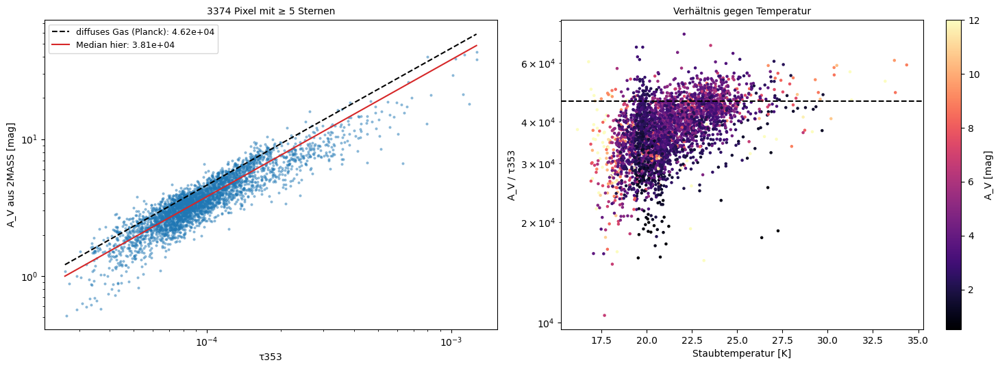

A_V/τ353: Median 3.81e+04 (16 % bis 84 %: 3.04e+04 bis 4.56e+04), diffus 4.62e+04: -18%
A_V  0.5 bis  3: 1211 Pixel, A_V/τ353 3.5e+04, T 20.5 K
A_V  3.0 bis  6: 1695 Pixel, A_V/τ353 4.02e+04, T 21.2 K
A_V  6.0 bis 10:  379 Pixel, A_V/τ353 4.03e+04, T 21.1 K
A_V 10.0 bis 40:   86 Pixel, A_V/τ353 3.37e+04, T 18.4 K
Rangkorrelation Verhältnis–Temperatur +0.53; A_V aus τ353: Maximum 50 mag (2MASS: 44)


In [12]:
ophiuchus.obscuring_vs_emitting()

**12. Die Masse der Wolke**

Aus der Extinktion folgt die Säule Wasserstoff, mit Helium die Masse pro Fläche, und mit der Entfernung die Fläche eines Pixels. Summiert wird über alle Pixel oberhalb einer Schwelle.

Über A_V = 1 liegen 4537 Sonnenmassen auf 47 pc², über A_V = 7 noch 1576 auf 6 pc², gut ein Drittel: die dichte Masse im Kern und in den Filamenten nach Osten, wo die jungen Sterne liegen. Die Planck-Karte gibt bei kleinen Schwellen dasselbe, bei großen mehr, weil 2MASS in den Kernen keine Sterne mehr sieht.

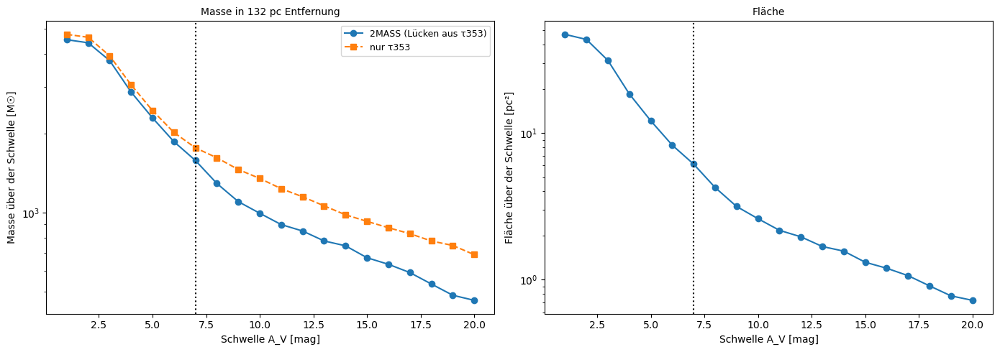

Ein Pixel: 0.115 pc Kantenlänge, 0.270 M☉ pro Magnitude A_V
A_V >  1: 2MASS    4537 M☉ auf  47.0 pc², nur τ    4754 M☉
A_V >  3: 2MASS    3779 M☉ auf  31.2 pc², nur τ    3940 M☉
A_V >  7: 2MASS    1576 M☉ auf   6.1 pc², nur τ    1761 M☉
A_V > 15: 2MASS     673 M☉ auf   1.3 pc², nur τ     925 M☉
Anteil der Masse über A_V = 7 an der über A_V = 1: 35%; ganzes Feld 4543 M☉


In [13]:
ophiuchus.mass()

**13. Die Entfernung gegen VLBI und Hipparcos**

Die eigene Entfernung neben den Radio-Parallaxen junger Sterne (Ortiz-León et al. 2017) und der älteren Messung mit derselben Methode aus Hipparcos (Lombardi et al. 2008); dazu Prüfungen mit anderen Schnitten, ohne Nullpunkt von Gaia und für die beiden Feldhälften.

Die Prüfungen ergeben 131.0 bis 133.0 pc, das Ergebnis ist 131.5 ± 1.0 ± 0.7 pc. VLBI misst für L1688 5.8 pc mehr: Die Stufe misst die Vorderkante des Staubs, die jungen Sterne sitzen tiefer in der Wolke. Hipparcos gab 2008 noch 119 ± 6 pc, aus wenigen hellen Sternen; heute sind es tausend mit hundertmal besseren Parallaxen.

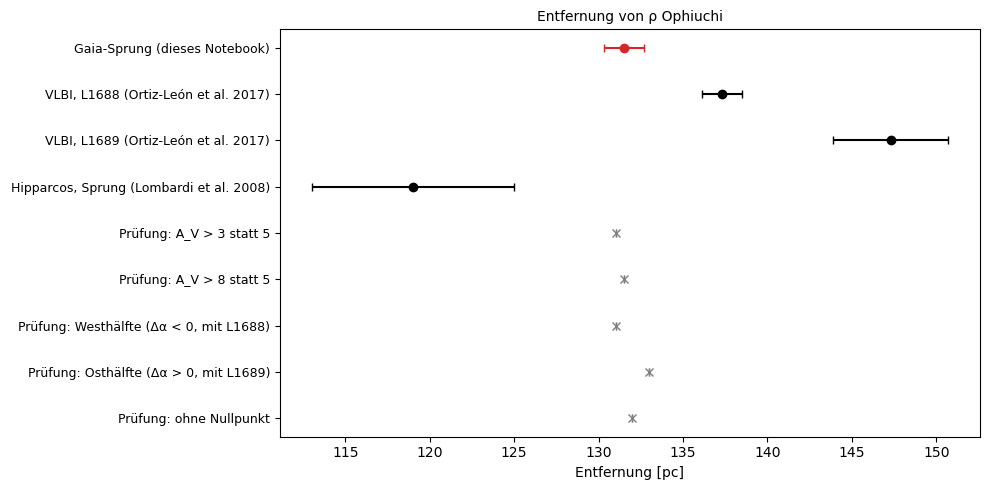

Gaia-Sprung: 131.5 ± 1.0 (Bootstrap) ± 0.7 (Schnitte, Nullpunkt) pc
  A_V > 3 statt 5         :  131.0 pc
  A_V > 8 statt 5         :  131.5 pc
  Westhälfte (Δα < 0, mit L1688):  131.0 pc
  Osthälfte (Δα > 0, mit L1689):  133.0 pc
  ohne Nullpunkt          :  132.0 pc
VLBI, L1688 (Ortiz-León et al. 2017)      :  137.3 ± 1.2 pc, Unterschied -5.8 pc
VLBI, L1689 (Ortiz-León et al. 2017)      :  147.3 ± 3.4 pc, Unterschied -15.8 pc
Hipparcos, Sprung (Lombardi et al. 2008)  :  119.0 ± 6.0 pc, Unterschied +12.5 pc


In [14]:
ophiuchus.distance_check()

**14. Die Extinktion gegen die Staubkarte von Schlegel, Finkbeiner und Davis**

Die meistbenutzte Staubkarte der Astronomie (SFD 1998) rechnet die 100-µm-Strahlung mit einer groben Temperaturkarte (1°) in Extinktion um; fast jedes extragalaktische Objekt wird damit korrigiert. Verglichen wird Pixel für Pixel mit der Karte aus 2MASS.

Wo der Staub wärmer ist, als die grobe Karte annimmt, überschätzt SFD die Extinktion (1.58-fach über 23 K), in kaltem Staub kaum (1.08). Das Muster ist genau das der Temperaturkarte. Im extremsten Pixel neben HD 147889 gibt SFD 62 mag statt 12.5: Ein Hintergrundobjekt würde dort um 50 mag zu hell korrigiert.

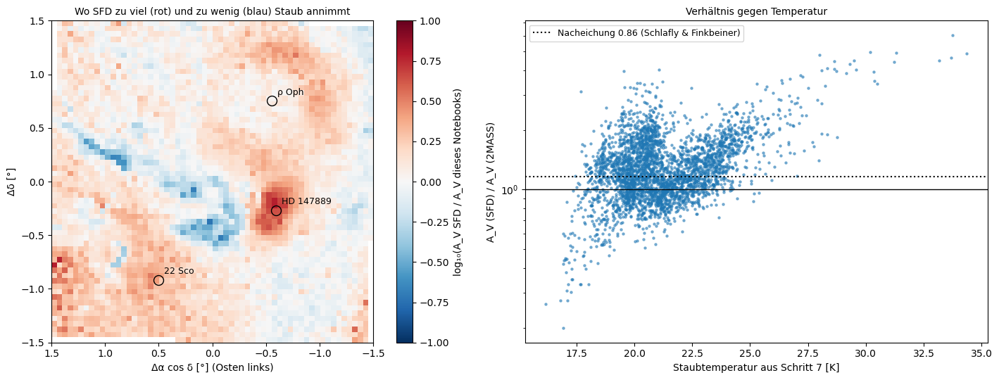

3309 Pixel: SFD/2MASS Median 1.24 (16 % bis 84 %: 0.91 bis 1.79); Rangkorrelation mit T +0.28
T 15 bis 19 K:  348 Pixel, SFD/2MASS 1.08
T 19 bis 21 K: 1436 Pixel, SFD/2MASS 1.25
T 21 bis 23 K:  882 Pixel, SFD/2MASS 1.11
T 23 bis 40 K:  643 Pixel, SFD/2MASS 1.58
Pixel ohne SFD-Wert (Rand des Ausschnitts): 67
Größtes A_V in SFD: 62 mag bei T = 31.3 K, 4.7′ von HD 147889; 2MASS/τ dort 12.5 mag


In [15]:
ophiuchus.sfd()

**15. Orion: Bilder und Kataloge**

Der Orionnebel ist das nächste große Gebiet, in dem massereiche Sterne entstehen, mit bloßem Auge im Schwert des Orion zu sehen. In seiner Mitte steht das Trapez; einer seiner Sterne, θ¹ Orionis C, ein O-Stern mit rund 30 Sonnenmassen, ionisiert mit seinem UV-Licht die Oberfläche einer dichten Molekülwolke. Geladen werden Karten aus SkyView in 19 Bändern vom Röntgen bis zum Radio (3° × 3°) und in acht Bändern für Farbbilder (1° × 1°), dazu Parallaxen aus Gaia DR3 und Helligkeiten aus 2MASS über den TAP-Dienst von IRSA.

Die Ausgabe listet die geladenen Karten und Kataloge; alles liegt im Cache unter `data/nebulae/orion/`.

In [16]:
orion.load()

19 Übersichtskarten (3°), 9 Karten für Farbbilder (1°); Gaia: 971 Sterne bis 15′; 2MASS: 2311 Quellen bis 10′ um das Trapez, 794 im Vergleichsfeld
Pixel der Übersicht 30″, Öffnung 40′, Hintergrund 60–85′


**16. Der Orionnebel vom Röntgen- bis zum Radiobereich**

Zwölf der 19 Übersichtskarten nebeneinander, nach Wellenlänge geordnet: Röntgen zeigt junge, aktive Sterne, Hα das ionisierte Gas, das nahe Infrarot die Sterne durch den Staub hindurch, das ferne Infrarot und der Submillimeterbereich kalten Staub, das Radio die Strahlung des ionisierten Gases. Der Kreis ist die Öffnung von 40′ für die Photometrie.

In den scharfen Bildern (ROSAT, 2MASS K, NVSS) sitzt das hellste Pixel genau beim Trapez. Der warme Staub bildet einen Fleck mit einem Ausläufer nach Norden zu M 43, der kalte Staub bei 350 und 850 µm ein langes Band von Nord nach Süd: die Molekülwolke Orion A, deren Spitze der Nebel ist. Bei 350 µm liegt das hellste Pixel 1.1′ nordwestlich, wo hinter dem Nebel der dichte Kern OMC-1 liegt. Drei Bilder zeigen Fehler der Geräte: SHASSA ist im Kern übersättigt, 2MASS K aus Kacheln zusammengesetzt, und NVSS sieht als Interferometer keine großen Strukturen.

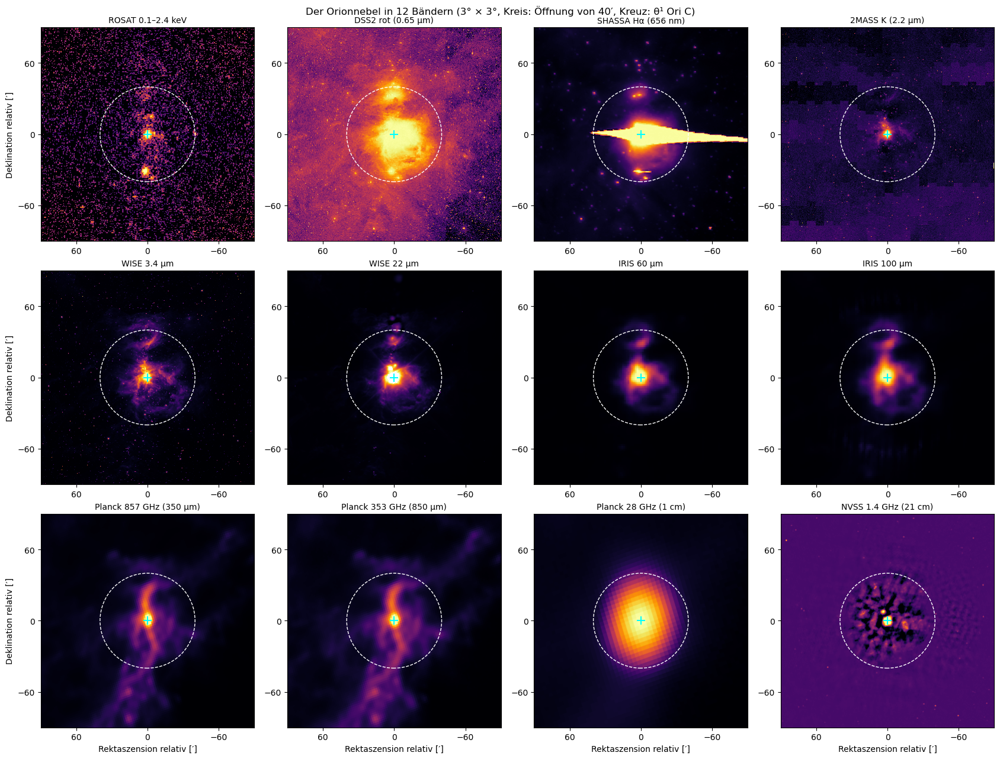

ROSAT 0.1–2.4 keV         : hellstes Pixel   0.4′ vom Trapez (Ost  -0.2′, Nord  -0.2′)
DSS2 rot (0.65 µm)        : hellstes Pixel  24.3′ vom Trapez (Ost +21.2′, Nord -11.8′)
SHASSA Hα (656 nm)        : hellstes Pixel  19.0′ vom Trapez (Ost +18.8′, Nord  -2.8′)
2MASS K (2.2 µm)          : hellstes Pixel   0.4′ vom Trapez (Ost  -0.2′, Nord  -0.2′)
WISE 3.4 µm               : hellstes Pixel   0.8′ vom Trapez (Ost  -0.2′, Nord  -0.8′)
WISE 22 µm                : hellstes Pixel   4.4′ vom Trapez (Ost  -1.2′, Nord  -4.2′)
IRIS 60 µm                : hellstes Pixel   3.3′ vom Trapez (Ost  +3.2′, Nord  +0.8′)
IRIS 100 µm               : hellstes Pixel   2.3′ vom Trapez (Ost  +0.2′, Nord  -2.2′)
Planck 857 GHz (350 µm)   : hellstes Pixel   1.1′ vom Trapez (Ost  -0.8′, Nord  +0.8′)
Planck 353 GHz (850 µm)   : hellstes Pixel   0.8′ vom Trapez (Ost  +0.8′, Nord  +0.2′)
Planck 28 GHz (1 cm)      : hellstes Pixel   4.0′ vom Trapez (Ost  +1.2′, Nord  -3.8′)
NVSS 1.4 GHz (21 cm)      : hellstes Pixel 

In [17]:
orion.multiwavelength()

**17. Farbbilder in drei Wellenlängenbereichen**

Je drei Bänder werden als Rot, Grün und Blau gemischt: optisch aus Fotoplatten (DSS2), nahes Infrarot aus 2MASS (J, H, K) und mittleres Infrarot aus WISE (3.4, 4.6, 12 µm). Dazu werden in 2MASS die Sterne bis 10′ um das Trapez gezählt.

Optisch leuchtet das ionisierte Gas, durchzogen von dunklen Staubbändern. Im nahen Infrarot verschwindet der Nebel fast, stattdessen erscheint ein dichter Haufen rötlicher Sterne, die in oder hinter Staub stecken: 784 Punktquellen bei 1.25 µm und 867 bei 2.2 µm, 11 % mehr, weil längere Wellen weniger vom Staub geschluckt werden. Im mittleren Infrarot leuchtet warmer Staub mit großen Molekülen (PAH) in Fasern und Bögen.

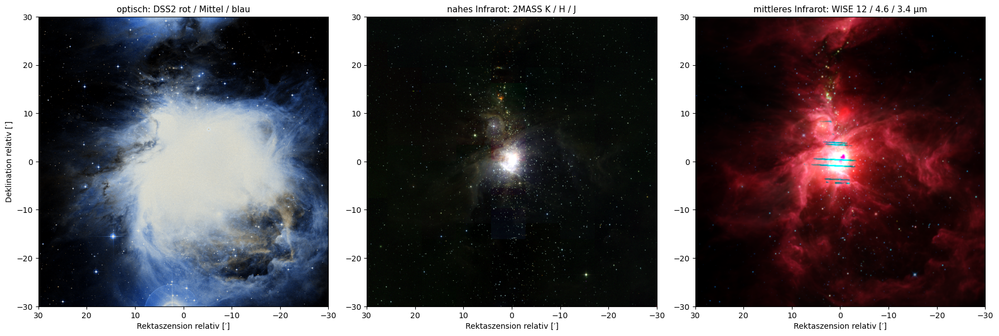

2MASS-J  :  784 Punktquellen über 8σ bis 10′ um das Trapez


2MASS-K  :  867 Punktquellen über 8σ bis 10′ um das Trapez


In [18]:
orion.color_images()

**18. Die Entfernung aus Gaia**

Alle Sterne bis 15′ um das Trapez mit Parallaxe auf 10 % genau; Mitglieder des Haufens sind die mit 2.0 bis 3.5 Millibogensekunden. Gemittelt wird gewichtet, nach Korrektur um den Nullpunkt von Gaia, und verglichen mit zwei Messungen der Radio-Interferometrie (VLBA).

Die 915 Mitglieder bilden eine schmale Spitze bei 2.567 mas, also 389.5 ± 1.5 pc; der größere Teil des Fehlers kommt aus dem Nullpunkt. Kounkel et al. (388 ± 5 pc) liegen 0.3σ entfernt, die ältere VLBA-Messung von Menten et al. (414 ± 7 pc) 3.4σ; sie beruhte auf wenigen Sternen.

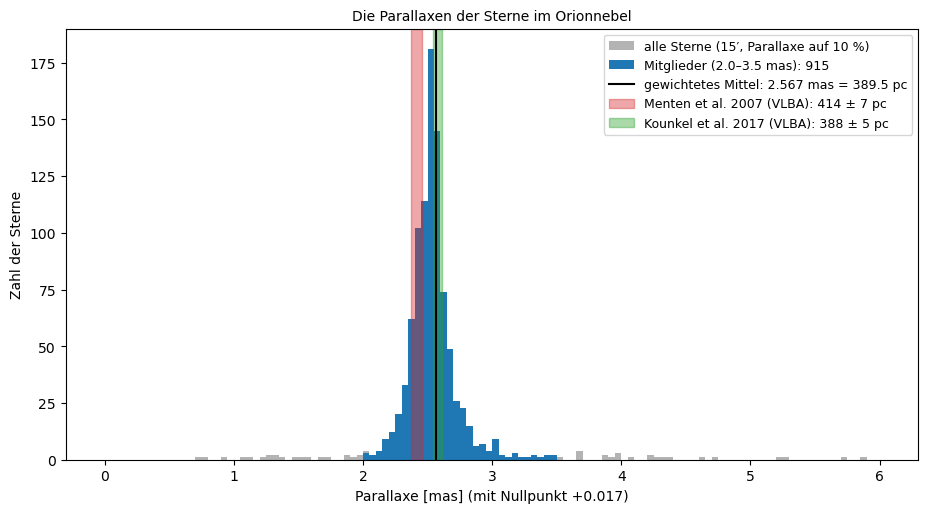

Mitglieder 915 von 971; Parallaxe 2.5671 ± 0.0016 mas (Streuung der Sterne 0.177 mas)
Entfernung 389.5 ± 1.5 pc (statistisch ± 0.2, Nullpunkt ± 1.5; Median der Sterne 396.0 pc; ohne Nullpunkt 392.1 pc)
  gegen Menten et al. 2007 (VLBA): -3.4 σ
  gegen Kounkel et al. 2017 (VLBA): +0.3 σ


In [19]:
orion.distance()

**19. Photometrie der ganzen Region**

Alle geeichten Karten werden in Jy/sr umgerechnet, und der Fluss wird in Öffnungen von 5′ bis 55′ um das Trapez gemessen, mit dem Hintergrund aus einem Ring von 60′ bis 85′. Die Wachstumskurven zeigen, ob die Öffnung groß genug ist.

Bei 12 µm stammt die Hälfte des Flusses aus den innersten 5′, bei 28 GHz nur 6 %, weil die Radiokarten den Nebel auf 33′ verschmieren. Bei 40′ sind die meisten Kurven flach; bei 350 und 850 µm wachsen sie weiter, weil dort die ausgedehnte Molekülwolke leuchtet. Die Flüsse bei 40′ reichen von 357 Jy bei 28 GHz bis 568 743 Jy bei 100 µm.

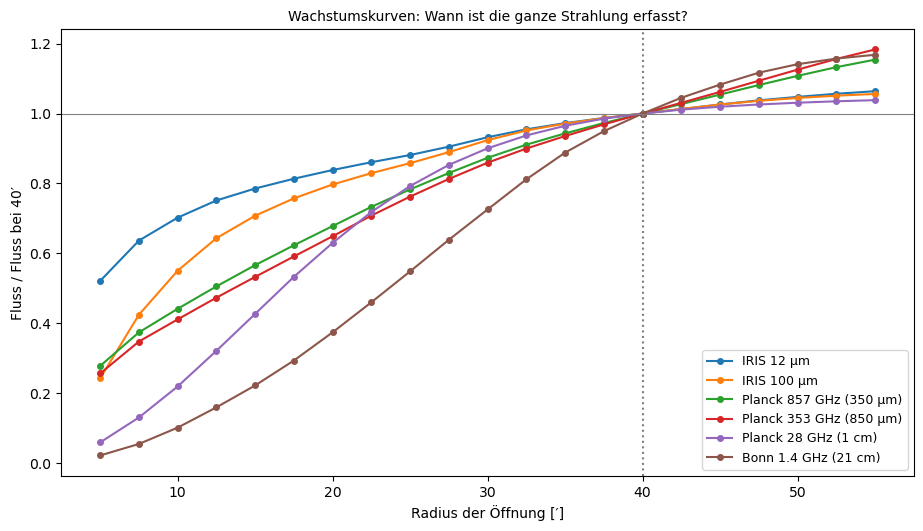

IRIS 12 µm                 ν =  25000.0 GHz: S =    29067.3 ±   374.0 Jy
IRIS 25 µm                 ν =  12000.0 GHz: S =   120645.2 ±   667.7 Jy
IRIS 60 µm                 ν =   5000.0 GHz: S =   444707.4 ±  2135.1 Jy
IRIS 100 µm                ν =   3000.0 GHz: S =   568743.3 ±  9780.5 Jy
Planck 857 GHz (350 µm)    ν =    857.0 GHz: S =    96545.9 ±  9311.5 Jy
Planck 545 GHz (550 µm)    ν =    545.0 GHz: S =    26677.6 ±  3236.3 Jy
Planck 353 GHz (850 µm)    ν =    353.0 GHz: S =     7228.5 ±   945.8 Jy
Planck 217 GHz (1.4 mm)    ν =    217.0 GHz: S =     1906.0 ±   252.7 Jy
Planck 70 GHz (4.3 mm)     ν =     70.4 GHz: S =      357.7 ±     6.1 Jy
Planck 44 GHz (6.8 mm)     ν =     44.1 GHz: S =      350.2 ±     3.7 Jy
Planck 28 GHz (1 cm)       ν =     28.4 GHz: S =      357.2 ±     4.2 Jy
Bonn 1.4 GHz (21 cm)       ν =      1.4 GHz: S =      141.0 ±     1.4 Jy


In [20]:
orion.region_photometry()

**20. Frei-frei-Strahlung und der Stern, der den Nebel ionisiert**

Elektronen, die an Ionen vorbeifliegen, strahlen im Radio (frei-frei); ihr Fluss zählt, wie viele ionisierende Photonen der Nebel pro Sekunde verbraucht. An die Planck-Flüsse bei 28, 44 und 70 GHz wird ein Potenzgesetz angepasst, und aus 28 GHz und der Entfernung folgt die Zahl Q der ionisierenden Photonen, verglichen mit der Kalibration von O-Sternen (Martins et al. 2005).

Das Radiospektrum ist fast flach (357, 350, 358 Jy; Exponent −0.006), wie für frei-frei-Strahlung. Daraus folgen Q = 5.7·10⁴⁸ Photonen pro Sekunde, log Q = 48.76; ein O7-V-Stern liefert 48.75. Der Nebel braucht also genau so viel ionisierendes Licht, wie θ¹ Ori C abgibt. Die Karte bei 1.4 GHz (Bonn) liegt weit unter dem erwarteten Wert und geht in keine Rechnung ein.

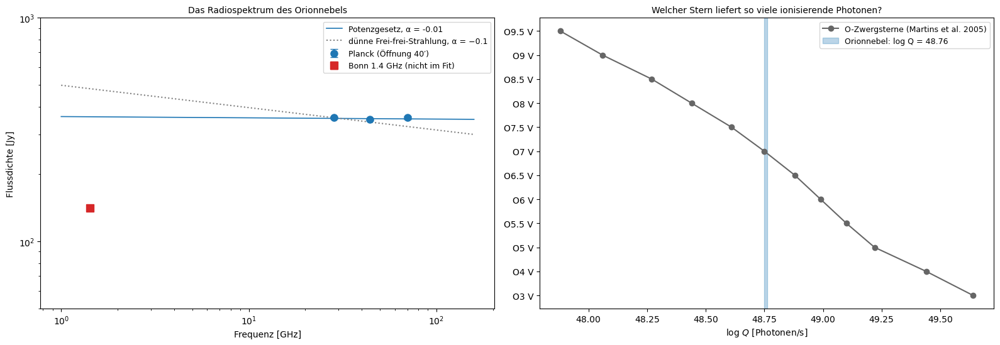

Spektralindex 28–70 GHz: α = -0.006; S(28 GHz) = 357.2 ± 4.2 Jy, Bonn 1.4 GHz 141.0 Jy (erwartet mit α = −0.1: 482 Jy)
L_ν(28 GHz) = 6.49e+22 erg/s/Hz, Q = 5.71e+48 ± 8.1e+46 s⁻¹ (log Q = 48.76); passt zu O7 V (log Q = 48.75)


In [21]:
orion.free_free()

**21. Wie viel Staub vor den Sternen liegt**

Hα lässt sich nicht verwenden, weil SHASSA im Kern übersättigt ist. Stattdessen geben die Farben der Sterne aus 2MASS die Extinktion: Staub rötet das Licht, und aus der Farbe J − H gegen die eines Vergleichsfelds folgt A_V.

Das Vergleichsfeld liegt um null, die Haufensterne fast alle darüber: im Median A_V = 3.8 mag, zwischen 1.3 und 8.5 mag, 37 % über 5 mag. Die stark geröteten Sterne häufen sich 2 bis 8′ nördlich des Trapezes entlang des dichten Staubbands, das bei 350 µm von OMC-1 nach Norden läuft; im Optischen sind sie kaum zu sehen.

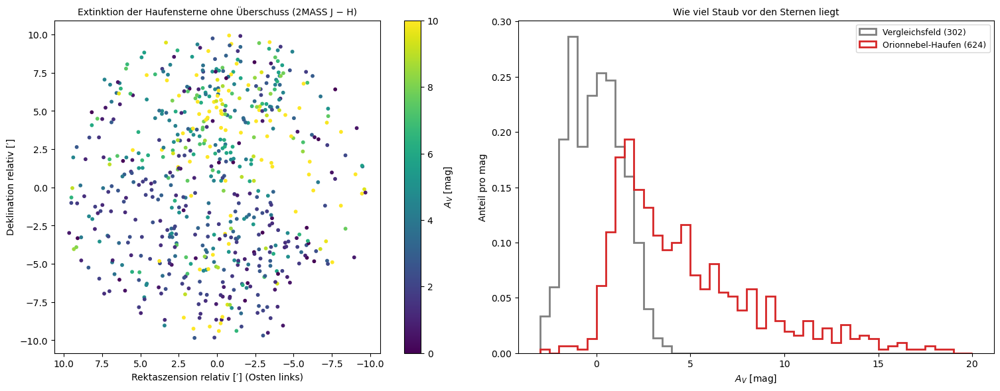

SHASSA übersättigt (über 9·10⁴ dR) auf 1063 Quadratbogenminuten
Eigenfarbe (J − H)₀ = 0.570 (Median im Vergleichsfeld)
A_V Haufen: Median 3.78 mag, 16. bis 84. Perzentil 1.32 bis 8.51, Anteil über 5 mag 0.37; Vergleichsfeld: Median 0.00, Streuung 1.37 mag
Sterne mit A_V über 5 mag liegen im Median 6.0′ vom Trapez, die übrigen 6.4′


In [22]:
orion.extinction()

**22. Dichte, Größe und die Strömgren-Kugel**

Ein Stern ionisiert um sich eine Kugel, bis die Rekombinationen alle Photonen aufbrauchen (Strömgren-Kugel). Die Dichte im Kern folgt aus der Helligkeitstemperatur bei 1.4 GHz (NVSS), Größe und mittlere Dichte des ganzen Gebiets aus einer Gaußglocke an die Karte bei 70 GHz.

Im Kern ist das Gas bei 1.4 GHz halb undurchsichtig (τ = 0.61), mit einer Dichte von etwa 6100 Elektronen pro cm³. Das ganze Gebiet hat einen Radius von 0.30 pc, eine mittlere Dichte von 2600 cm⁻³ und 10 Sonnenmassen ionisiertes Gas. Der Radius liegt fast genau auf der Strömgren-Kurve: So weit reichen die Photonen von θ¹ Ori C.

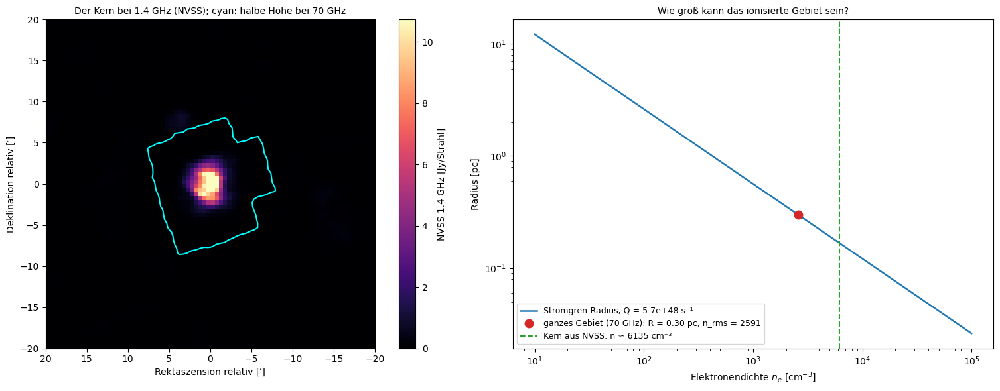

NVSS: Spitze 14.8 Jy/Strahl → T_b = 4561 K, τ(1.4 GHz) = 0.61, EM = 3.76e+06 pc cm⁻⁶, n ≈ 6135 cm⁻³ (0.1 pc); τ(28 GHz) = 0.0011
70 GHz: FWHM 16.3′ × 13.6′, ohne Strahl 9.5′ × 2.9′ → R = 0.30 pc; n_rms = 2591 cm⁻³, Masse 10.0 M☉; Füllfaktor (n_rms/n_Kern)² = 0.18
Strömgren-Radius: n = 10³ → 0.56 pc, n = 6135 → 0.17 pc


In [23]:
orion.density()

**23. Das Spektrum der ganzen Region**

Die Flüsse von 28 GHz bis 12 µm als Spektrum. Nach Abzug der frei-frei-Strahlung wird an den Staub ein modifizierter Schwarzkörper angepasst; daraus folgen Temperatur, Leuchtkraft und Masse.

Unter 100 GHz dominiert das ionisierte Gas, darüber der Staub; bei 12 und 25 µm leuchten kleine, heiße Körner, die eine einzelne Temperatur nicht beschreibt. Der Staub hat 36.8 ± 2.8 K, das Maximum liegt bei 60 µm. Die Infrarot-Leuchtkraft ist 2.2·10⁵ Sonnenleuchtkräfte, das 1.6-Fache eines O7-V-Sterns: Die übrigen Trapezsterne und eingebettete junge Sterne heizen mit. Aus 353 GHz folgen 1560 Sonnenmassen Gas und Staub, 150-mal mehr als ionisiertes Gas.

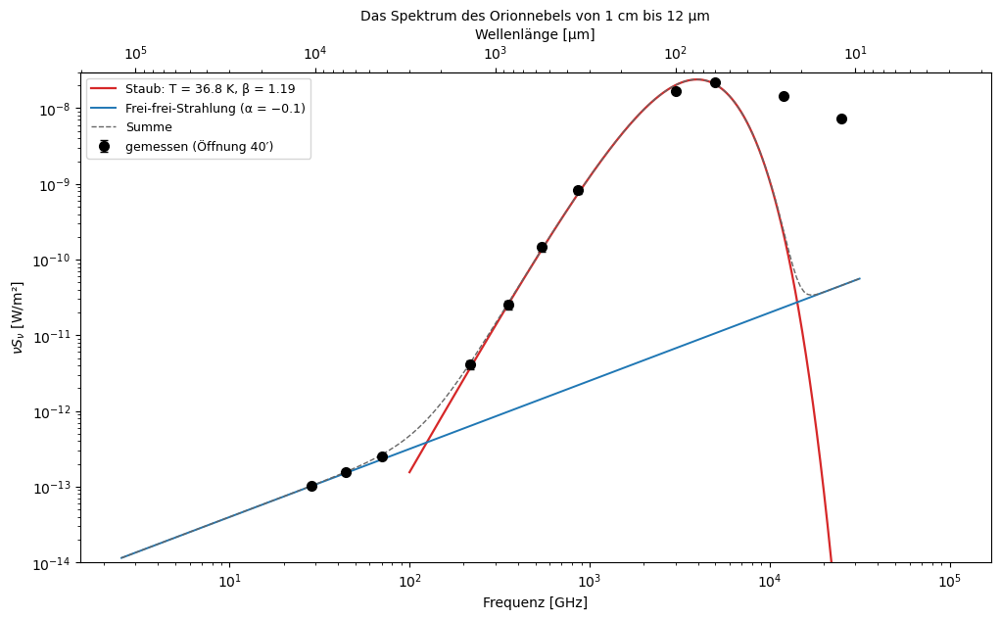

Staub: T = 36.8 ± 2.8 K, β = 1.19 ± 0.14; Maximum von νS_ν bei 60 µm
Infrarot-Leuchtkraft: Modell 1.31e+05 L☉, Messpunkte 2.23e+05 L☉; O7 V nach Martins: 1.38e+05 L☉ (Verhältnis Messpunkte/O7 V = 1.6)
Masse von Gas und Staub aus 353 GHz: 1562 M☉; ionisiertes Gas (Schritt 22): 10 M☉


In [24]:
orion.spectrum()

**24. Eine Karte der Staubtemperatur**

Für jedes Pixel folgt aus dem Verhältnis der Helligkeiten bei 60 und 100 µm (IRIS) die Temperatur des Staubs. Heizt ein einzelner Stern, sollte sie wie r^(−0.36) mit dem Abstand fallen.

Am wärmsten (bis 47 K) ist der Staub nahe dem Kern, nach außen fällt die Temperatur auf 32 K bei 40′. Sie fällt aber flacher als erwartet (Steigung −0.13 statt −0.36): Im Kern verschmiert die Auflösung die heißesten Stellen, weiter außen heizen das Sternlicht der Milchstraße und andere Sterne mit. θ¹ Ori C dominiert den Staub nur im Inneren.

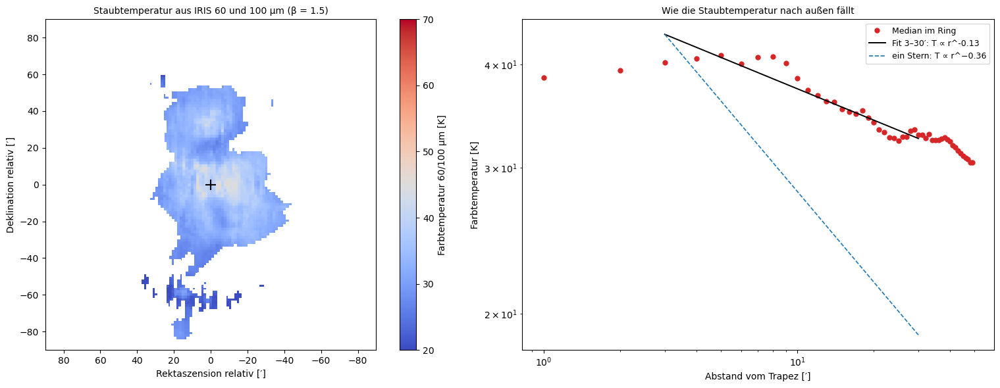

Farbtemperatur: Maximum 47.3 K, bei 5′ 41.1 K, bei 20′ 34.0 K, bei 40′ 32.3 K; Steigung -0.13 (ein Stern: −0.36)


In [25]:
orion.dust_temperature()

**25. Junge Sterne mit Infrarot-Überschuss**

Junge Sterne mit einer Scheibe leuchten im nahen Infrarot heller, als ihre Farbe verlangt, weil die heiße innere Scheibe zusätzlich strahlt. Gezählt werden die Sterne bis 10′ um das Trapez, die im Farbdiagramm rechts der Rötungsgeraden liegen, und dieselben in einem Vergleichsfeld.

Im Haufen haben 249 von 873 Sternen (28.5 %) einen Überschuss, im Vergleichsfeld 13 von 315 (4.1 %), das sind Fehlalarme. Korrigiert hat ein Viertel der Sterne eine Scheibe, die man in K sieht. Hillenbrand et al. (1998) fanden mit einem längeren Hebel (I − K) 55 bis 90 %: J, H und K sehen nur Scheiben mit heißem innerem Rand.

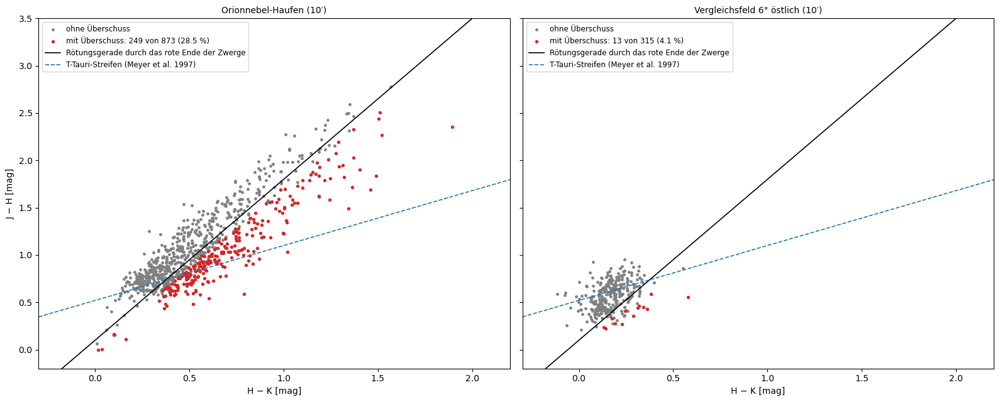

Orionnebel-Haufen: 249 von 873 mit Überschuss (28.5 %); Vergleichsfeld 13 von 315 (4.1 %); um Fehlalarme korrigiert 25.4 %
Hillenbrand et al. 1998 (aus I − K): mindestens 55 %, höchstens 90 %


In [26]:
orion.young_stars()

**26. Orion gegen die Literatur**

Fünf eigene Ergebnisse neben den veröffentlichten, jeweils als Verhältnis.

Entfernung (389.5 pc) und Zahl der ionisierenden Photonen (log Q = 48.76 gegen 48.75 für O7 V) stimmen. Die Infrarot-Leuchtkraft liegt beim 1.6-Fachen eines O7-Sterns, weil mehr als ein Stern heizt, und der Anteil der Scheiben bei der Hälfte, weil J, H und K weniger empfindlich sind als I und K. Beide Abweichungen haben einen erklärbaren Grund.

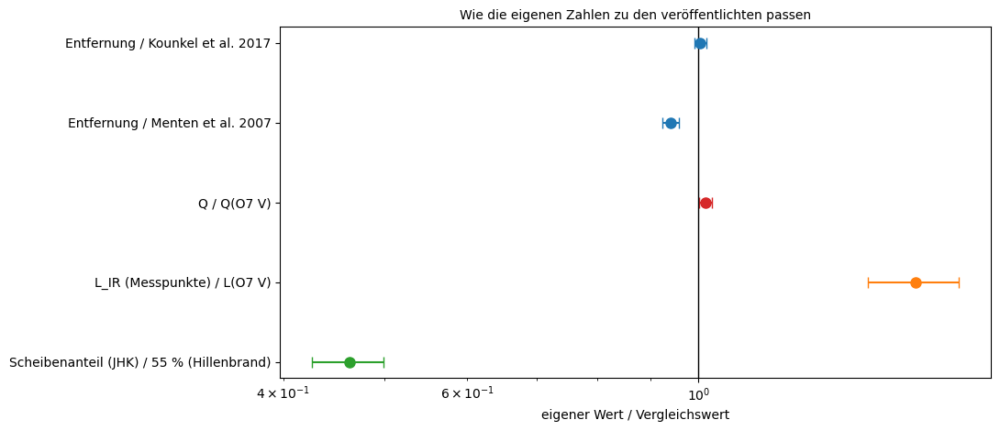

Entfernung 389.5 ± 1.5 pc; Kounkel 388 ± 5, Menten 414 ± 7
log Q = 48.76; O7 V: 48.75, O6 V: 48.99, O7.5 V: 48.61
L_IR = 2.23e+05 L☉ (Modell 1.31e+05); O7 V: 1.38e+05 L☉
Scheiben: 25.4 % (J, H, K); Hillenbrand et al. 1998: 55 bis 90 % (I − K)
A_V der Haufensterne: Median 3.78 mag (16. bis 84. Perzentil 1.32 bis 8.51)


In [27]:
orion.literature()

**27. H-II-Regionen: die Gaswolken von M 101 in SDSS**

H-II-Regionen sind Gaswolken, die junge, heiße Sterne ionisieren und zum Leuchten bringen; aus ihren Linien liest man, wie viel Sauerstoff das Gas enthält. Wie hell eine Linie pro Ion leuchtet, hängt aber exponentiell von der Temperatur ab, und die lässt sich messen: Dasselbe Ion strahlt aus zwei verschieden hohen Niveaus, und das Verhältnis der Linien wirkt als Thermometer. Die obere Linie ist 100- bis 500-mal schwächer; das Projekt CHAOS hat sie mit dem Large Binocular Telescope gemessen. Hier wird dasselbe mit den Spektren versucht, die der Sloan Digital Sky Survey (SDSS) auf die Galaxie M 101 gelegt hat, und an CHAOS geprüft.

Bei SDSS liegen 76 Spektren um die Galaxie, 54 auf Gas und 22 auf Vordergrundsternen. Die Fasern sitzen auf den blauen Knoten der Spiralarme und verteilen sich bis an den Rand der Scheibe, im Mittel weiter außen als die 102 CHAOS-Regionen; 14 Fasern treffen eine CHAOS-Region innerhalb von 3″.

Zentrum aus den CHAOS-Namen: RA 210.80207°, Dec 54.34886°; R25 = 14.4′ = 31.0 kpc bei 7.4 Mpc
Kontrolle: eigene Abstände R/R25 minus CHAOS: höchstens 0.0018
CHAOS: 102 Regionen, 74 mit mindestens einer gemessenen Temperatur, 77 mit O/H
SDSS: 76 Spektren; Klassen {'GALAXY': 54, 'STAR': 22}; Spektrographen {'SDSS': 52, 'BOSS': 24}
Fasern auf Gas: 54 (SDSS 48, BOSS 6); innerhalb von 3″ einer CHAOS-Region: 14


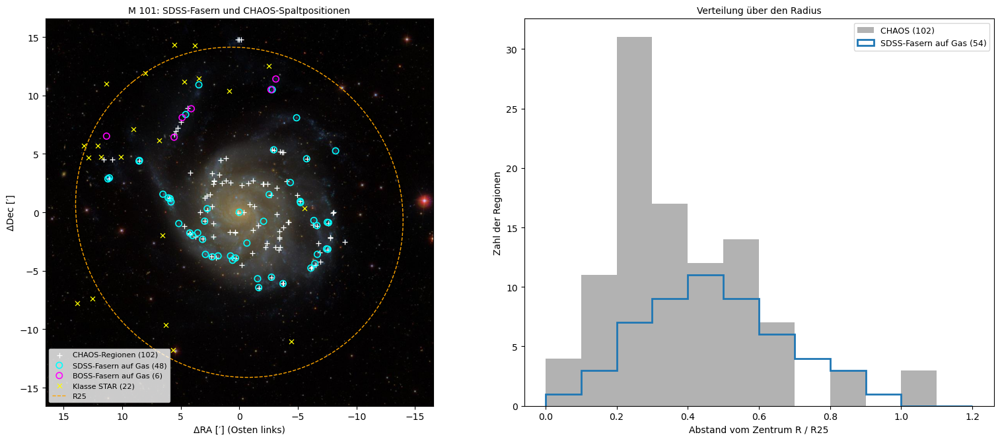

In [28]:
hii.regions()

**28. Erster Blick auf die schwachen Linien**

Das rohe Spektrum der Faser auf der hellen, metallarmen Riesenregion NGC 5471, vergrößert um die vier Temperaturlinien ([O III] 4363, [N II] 5755, [S III] 6312, [O II] 7320/7330).

Die starken Linien ragen weit über das Licht der Sterne. Bei [O III] 5007 und Hα fehlen die Werte im Kern: Der Detektor war gesättigt, ausgerechnet in der hellsten Region. [O III] 4363 erreicht hier ein Viertel der Höhe von Hγ, weil das Gas heiß ist; [N II] 5755 hebt sich kaum aus dem Rauschen. In metallreichen Regionen wird 4363 hundertmal schwächer.

Faser 1491914454806325248 (SDSS), 4.4″ von einer CHAOS-Position in NGC 5471, R/R25 = 0.82
  Hb       : 0 maskierte Pixel im Linienkern
  OIII5007 : 5 maskierte Pixel im Linienkern
  Ha       : 4 maskierte Pixel im Linienkern
  OIII4363 : 0 maskierte Pixel im Linienkern
Spitzenhöhe über dem Kontinuum relativ zu Hγ: OIII4363 0.225, NII5755 0.003, SIII6312 0.026, OII7320 0.026, OII7330 0.021


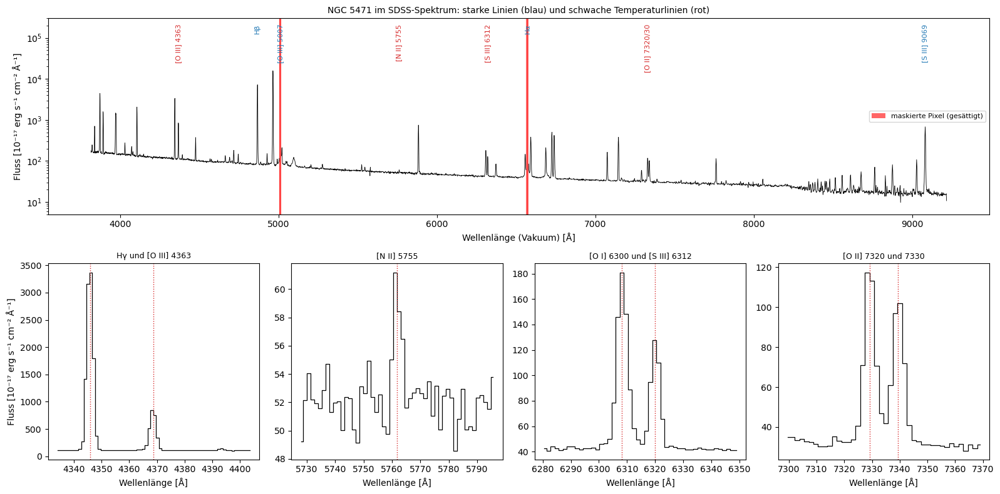

In [29]:
hii.weak_lines()

**29. Linienfits mit fester Lage und Breite**

Eine schwache Linie misst man am sichersten mit wenig freien Parametern: Lage und Breite kommen aus den starken Linien, frei bleibt nur die Höhe. Dieselbe Messung an Stellen ohne Linie (Leermessungen) zeigt, wie oft das Rauschen eine Linie vortäuscht.

Auch knappe Nachweise (Signal-Rausch 5) treffen eine Erhebung genau an der erwarteten Stelle. Die 540 Leermessungen folgen fast der Gaußkurve, die Fehler der Pipeline sind etwa 10 % zu klein, und keine erreicht S/N 5: Die Schwelle 5 schließt zufällige Nachweise praktisch aus. Mit S/N über 5 gibt es [O III] 4363 in 15 Fasern, [N II] 5755 in 10, [S III] 6312 in 21 und [O II] 7320/7330 in 23 bis 24.

54 Fasern angepasst; Breite der Linien im Median 1.11-mal die Instrumentbreite
Leermessungen: 540, Mittel +0.05, Streuung 1.11 (robust 1.08); |S/N| > 3: 1.1% (Gauß: 0.3 %); S/N > 5: 0
Linie       gemessen  S/N > 3  S/N > 5
OIII4363          54       23       15
NII5755           54       17       10
SIII6312          54       26       21
OII7320           54       26       24
OII7330           54       26       23
SIII9069          53       34       32
SIII9532           6        1        0
OII3726            6        4        4


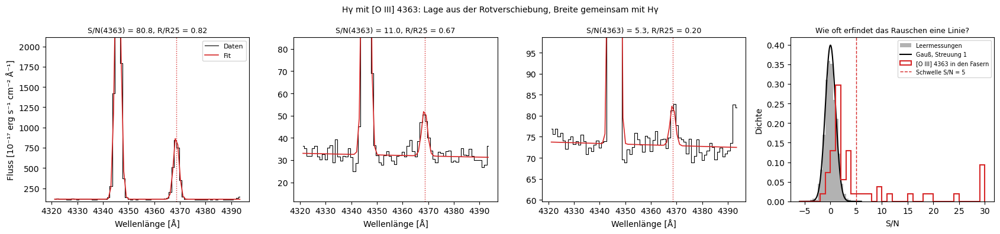

In [30]:
hii.line_fits()

**30. Gesättigte Linien und Staub**

[O III] 4959 und 5007 kommen aus demselben Niveau, ihr Verhältnis liegt fest (2.98); wo 5007 gesättigt ist, ersetzt es 2.98 × 4959. Staub schwächt blaues Licht stärker als rotes; die Rötung folgt aus Hα/Hβ, dessen Wert ohne Staub die Atomphysik festlegt.

Gemessen ist 5007/4959 im Median 3.00, wie vorhergesagt; in 3 Fasern wird 5007 ersetzt. Hγ/Hβ taugt kaum als Ersatz für die Rötung, weil die Linien zu nah beieinander liegen. Die Rötung ist im Median 0.21 mag; sie schwächt 4363 um 12 % mehr als 5007, ohne Korrektur käme die Temperatur um etwa 400 K zu niedrig heraus.

Theorie: 5007/4959 = 2.984; gemessen in 26 Fasern (S/N > 20): Median 3.000, Streuung 0.113
[O III] 5007 gesättigt und aus 4959 ersetzt: 3 Fasern; Hα gesättigt: 4
Staub aus Hα/Hβ: 43 Fasern, aus Hγ/Hβ: 4, ohne Staubwert: 7
E(B−V): Median 0.21 mag (16.–84. Perzentil 0.08 bis 0.47)
Hα/Hβ gegen Hγ/Hβ in 17 hellen Fasern: Unterschied im Median +0.057 mag, Streuung 0.159 mag
Lichtverlust durch Staub bei E(B−V) = 0.21: [O III] 4363 gegenüber 5007 um 12% stärker geschwächt, [S III] 6312 gegenüber 9069 um 21%


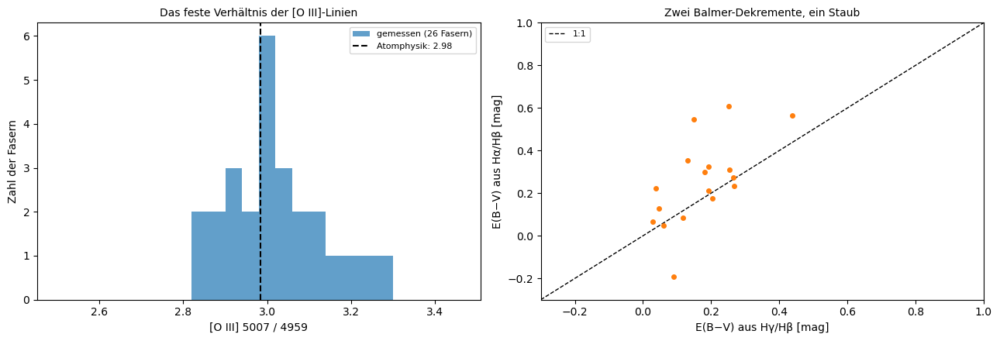

In [31]:
hii.saturation()

**31. Die Dichte**

Das Verhältnis des [S II]-Dubletts 6717/6731 hängt von der Dichte ab; ein selbst gelöstes Fünf-Niveau-Atom rechnet die Kurve. Dazu die Gegenprobe, wie stark eine falsch angenommene Dichte die Temperaturen verschiebt.

Das Verhältnis ist im Median 1.38, das Gas hat also etwa 60 Elektronen pro cm³ und ist dünn. Bis 1000 cm⁻³ ändern sich alle drei Thermometer um weniger als 1 %; erst über 10⁴ cm⁻³ fällt T[N II] deutlich ab. Für die Temperaturen ist die genaue Dichte also unwichtig.

[S II] 6717/6731 in 50 Fasern: Median 1.377 (16.–84. Perzentil 1.27 bis 1.45); Grenzwert für dünnes Gas 1.453
  -> n_e ≈ 60 cm⁻³ aus dem Median, 6 bis 161 cm⁻³ aus den Perzentilen; 14% liegen über dem Grenzwert


[O III]: angenommene Dichte 10 statt 100 cm⁻³ -> T = 10000 K, 1000 cm⁻³ -> 9992 K (wahr 10 000 K)


[N II]: angenommene Dichte 10 statt 100 cm⁻³ -> T = 10146 K, 1000 cm⁻³ -> 9928 K (wahr 10 000 K)


[S III]: angenommene Dichte 10 statt 100 cm⁻³ -> T = 10001 K, 1000 cm⁻³ -> 9986 K (wahr 10 000 K)


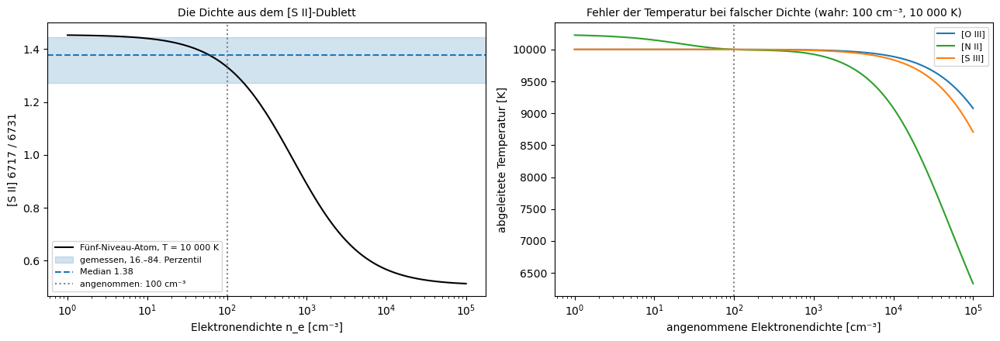

In [32]:
hii.density()

**32. Das Atom als Thermometer**

Für jedes Thermometer wird das Linienverhältnis zwischen 5000 und 25 000 K aus dem Fünf-Niveau-Atom tabelliert. Prüfung: Die Linien von CHAOS gehen durch dieselbe Tabelle.

Das [O III]-Verhältnis (4959 + 5007)/4363 ist 462 bei 8000 K, 204 bei 10 000 K und 96 bei 13 000 K: Gut 20 % mehr Temperatur verdoppeln die schwache Linie. Mit den Linien von CHAOS kommen fast dieselben Temperaturen heraus wie bei CHAOS, im Median −19 K für [O III], −102 K für [N II] und +6 K für [S III]. Für [S III] haben die SDSS-Fasern nur die Linie 9069; daraus wird T[S III] unsicherer.

[O III] (4959+5007)/4363 bei 10 000 K: Fünf-Niveau-Atom 204, Osterbrock & Ferland 212; bei 8000 K 462, bei 13 000 K 96
TO3 eigen minus CHAOS: 48 Regionen, Median -19 K, Streuung 22 K
TN2 eigen minus CHAOS: 39 Regionen, Median -102 K, Streuung 66 K
TS3 eigen minus CHAOS: 56 Regionen, Median +6 K, Streuung 117 K
T[S III] nur aus 9069 (9532 aus der Theorie, 2.47 × 9069): Median -82 K, Streuung 577 K; gemessen 9532/9069 bei CHAOS: Median 2.41, 16.–84. Perzentil 2.06 bis 3.32


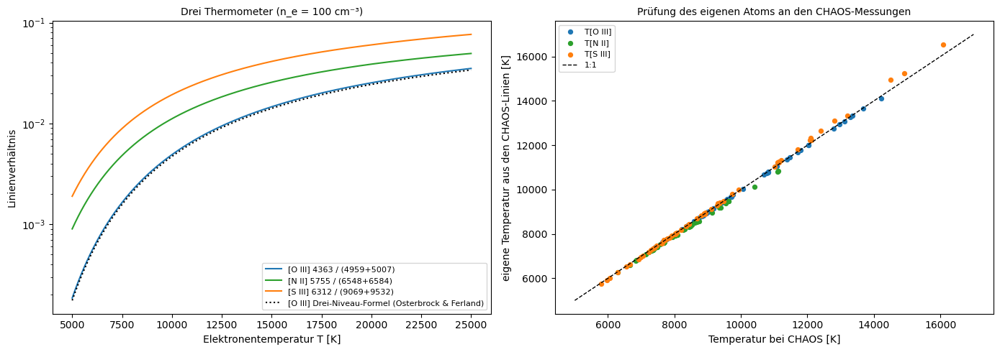

In [33]:
hii.thermometer()

**33. Die Temperaturen der Regionen**

Für jede Faser werden die Linienflüsse 500-mal aus ihren Fehlern gezogen und durch Entrötung und Thermometer geschickt; Median und Streuung geben Wert und Fehler.

T[O III] liegt in 14 Fasern zwischen 8356 und 13 109 K, mitten in der Wolke der CHAOS-Werte. Die Temperatur steigt nach außen, von 6690 K im Zentrum um 7081 K pro Scheibenradius: Innen ist mehr Sauerstoff, und Sauerstoff kühlt das Gas über seine Linien, die H-II-Region wirkt als Thermostat. Innerhalb von 0.2 Scheibenradien ist 4363 in einer einzelnen Faser zu schwach.

T_O3: 14 Fasern, 8356 bis 13109 K, Median 10468 K, Fehler im Median ±192 K
T_N2:  9 Fasern, 7442 bis 13399 K, Median 8605 K, Fehler im Median ±452 K
T_S3: 18 Fasern, 7455 bis 13797 K, Median 10168 K, Fehler im Median ±320 K
Gerade durch T[O III]: 6690 ± 700 K im Zentrum, +7081 ± 1215 K pro R25, innere Streuung 686 K
  CHAOS Te([OIII])1: 49 Regionen, 7420 bis 14220 K
  CHAOS Te([NII])1: 46 Regionen, 6300 bis 11200 K
  CHAOS Te([SIII])1: 59 Regionen, 5800 bis 16080 K


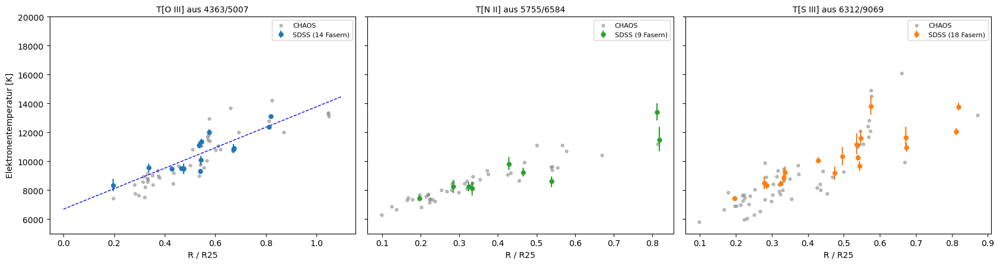

In [34]:
hii.region_temperatures()

**34. Temperatur gegen Temperatur**

Eine H-II-Region ist wie eine Zwiebel aufgebaut: innen O²⁺, außen O⁺ und N⁺, dazwischen S²⁺, und jedes Thermometer misst seine eigene Zone. Wo eine Faser zwei Thermometer hat, werden sie gegeneinander aufgetragen, mit den Beziehungen von CHAOS.

In heißem, metallarmem Gas ist die O⁺-Zone kälter als die O²⁺-Zone, in kühlem wärmer. Die 6 Fasern mit T[N II] und T[O III] liegen im Median 309 K unter der CHAOS-Beziehung, die 13 mit T[S III] 509 K, beide verträglich. Mit so wenigen Fasern lassen sich die Beziehungen nur prüfen; wo ein Thermometer fehlt, werden die von CHAOS übernommen.

T[N II] gegen T[O III]: 6 Fasern, Abweichung von der CHAOS-Beziehung Median -309 K, Streuung 1100 K; CHAOS selbst: Streuung 564 K (26 Regionen)
T[S III] gegen T[O III]: 13 Fasern, Abweichung von der CHAOS-Beziehung Median -509 K, Streuung 656 K; CHAOS selbst: Streuung 1103 K (38 Regionen)


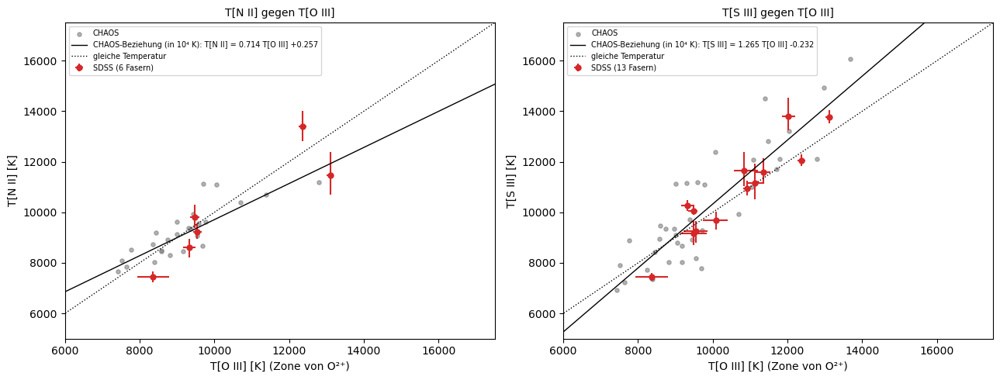

In [35]:
hii.tt_relations()

**35. Stapeln**

Mittelt man N Spektren, fällt das Rauschen wie 1/√N. Gestapelt werden die inneren Fasern ohne eigenen Nachweis von 4363, im Ruhesystem, entrötet und auf Hβ normiert.

Aus 9 Fasern, einzeln mit S/N unter 3.5, wird [O III] 4363 mit S/N 8.4 sichtbar; weil helle Fasern mehr Gewicht haben, zählen effektiv nur 4.3. Bei 4363 steckt vermutlich etwas [Fe II] 4359 mit drin, T[O III] ist darum eher eine Obergrenze. Die drei Temperaturen des Stapels passen zusammen, um 8000 K bei 0.3 Scheibenradien: Das Gas ist innen kühl.

Stapel aus 9 Fasern mit R/R25 < 0.45 und EW(Hβ) > 30 Å (Median R/R25 = 0.28), einzeln S/N(4363) zwischen -1.0 und 3.5
  effektive Zahl der Fasern (Σw)²/Σw² = 4.3; größter Anteil einer Faser 33%
  Hg        I/Hβ = 0.5096 ± 0.0030  (S/N 169.8)
  OIII4363  I/Hβ = 0.0045 ± 0.0005  (S/N 8.4)
  OIII5007  I/Hβ = 1.4532 ± 0.0060  (S/N 242.5)
  NII5755   I/Hβ = 0.0041 ± 0.0002  (S/N 19.1)
  NII6584   I/Hβ = 0.5541 ± 0.0013  (S/N 430.2)
  SIII6312  I/Hβ = 0.0087 ± 0.0002  (S/N 45.6)
  SIII9069  I/Hβ = 0.2175 ± 0.0009  (S/N 233.4)
  OII7320   I/Hβ = 0.0156 ± 0.0002  (S/N 66.5)
  OII7330   I/Hβ = 0.0133 ± 0.0002  (S/N 62.8)
  Ha        I/Hβ = 2.7941 ± 0.0063  (S/N 445.9)
  Kontrollen: 5007/4959 = 2.86 (Theorie 2.98), Hα/Hβ = 2.79 (Theorie 2.86)
  T_O3: 8136 (+230 / −250) K
  T_N2: 7821 (+129 / −128) K
  T_S3: 8191 (+62 / −68) K


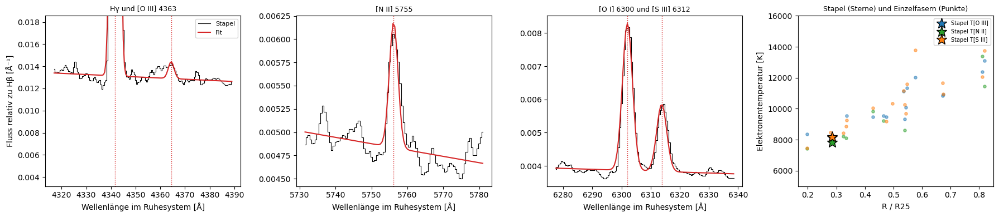

In [36]:
hii.stacking()

**36. Von der Temperatur zur Häufigkeit**

Wasserstoff dient als Maßstab: Die Häufigkeit eines Ions folgt aus seiner Linie relativ zu Hβ und dem Verhältnis der Emissivitäten bei der gemessenen Temperatur. Sauerstoff ist O⁺ plus O²⁺; O⁺ kommt hier aus [O II] 7320/7330, weil die üblichen Linien bei 3727 außerhalb des SDSS-Spektrums liegen.

Die Linien hängen steil an der Temperatur: 500 K mehr senken bei 8000 K die Häufigkeit von O²⁺ um 0.10 dex, eine zu hohe Temperatur ergibt also zu wenig Sauerstoff. Direkte Häufigkeiten gibt es in 19 Fasern, 12 + log(O/H) von 8.04 bis 8.65 mit ±0.065 dex. Auf den CHAOS-Daten ergeben 7320/7330 und 3727 dasselbe O⁺. Der Anteil von O²⁺ steigt von 17 % innen auf 77 % außen.

Direkte Sauerstoffhäufigkeit in 19 Fasern; Temperatur aus {'[O III]': 14, '[N II]': 3, '[S III]': 2}, O⁺ aus {'7320/7330': 19}
12 + log(O/H) von 8.04 bis 8.65, Fehler im Median ±0.065 dex; O²⁺-Anteil von 17% bis 77%
  T = 8000 K, +500 K: O²⁺ aus 5007       -0.104 dex
  T = 8000 K, +500 K: O⁺ aus 3727        -0.132 dex
  T = 8000 K, +500 K: O⁺ aus 7320/7330   -0.193 dex
  T = 12000 K, +500 K: O²⁺ aus 5007       -0.055 dex
  T = 12000 K, +500 K: O⁺ aus 3727        -0.067 dex
  T = 12000 K, +500 K: O⁺ aus 7320/7330   -0.094 dex
CHAOS-Regionen: log O⁺(7320/7330) − log O⁺(3727) = -0.008 im Median, Streuung 0.097 (67 Regionen)


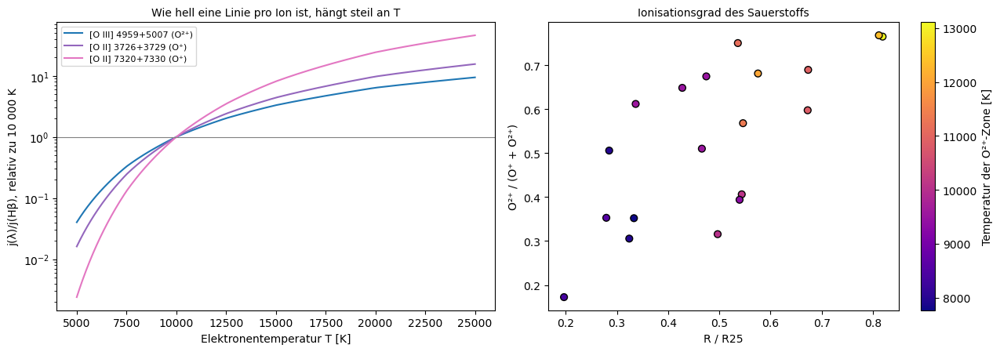

In [37]:
hii.abundances()

**37. Der direkte Metallizitätsgradient**

Durch die 19 Häufigkeiten wird eine Gerade gegen den Abstand vom Zentrum gelegt, mit einer inneren Streuung, so dass sie im Rahmen der Fehler passt.

Die Häufigkeit fällt nach außen: 12 + log(O/H) = 8.72 − 0.74 · R/R25, also 0.024 dex pro kpc. Im Zentrum ist sie etwa so hoch wie in der Sonne (8.69), am Scheibenrand 5.5-mal niedriger. Die Punkte streuen um 0.12 dex, mehr als die Messfehler erklären; 0.09 dex sind echte Unterschiede zwischen Regionen oder Fehler, die die Rechnung nicht kennt.

12 + log(O/H) = 8.717 ± 0.087 -0.742 ± 0.155 · R/R25   (19 Fasern)
  pro kpc: -0.0239 ± 0.0050 dex/kpc (R25 = 31.0 kpc); bei R25: 7.98
  Streuung um die Gerade 0.118 dex, innere Streuung 0.091 dex, Messfehler im Median 0.065 dex
  zum Vergleich die Sonne: 8.69 (Asplund et al. 2009); Abfall von der Mitte bis R25: 0.74 dex = Faktor 5.5


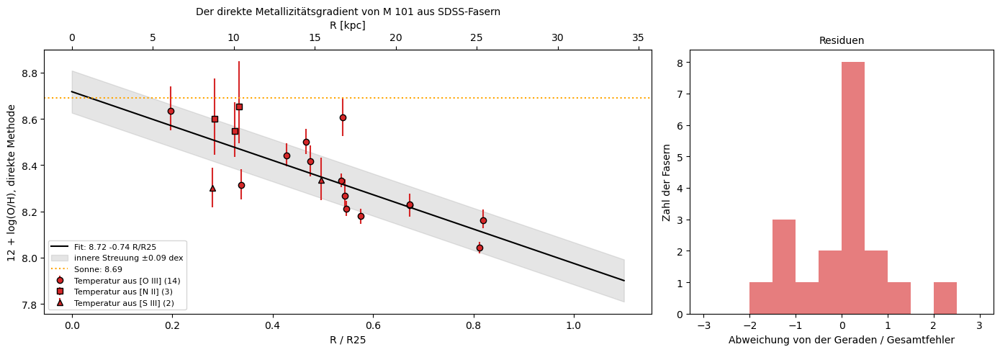

In [38]:
hii.gradient()

**38. Faser für Faser gegen CHAOS**

Für die 14 Fasern, die auf eine CHAOS-Region zeigen, werden Linienstärken, Temperaturen und Häufigkeiten verglichen.

Die Linienstärken liegen über drei Größenordnungen auf der 1:1-Linie. Hα streut nur um 0.03 dex, [N II] und [S II] um 0.15 bis 0.21 dex: Die runde Faser (3″) und der schmale Spalt (1″) sehen verschiedene Teile einer Region. T[O III] stimmt in 5 von 6 Paaren auf 150 K, O/H in 9 Paaren im Median auf 0.014 dex bei 0.12 dex Streuung.

14 SDSS-Fasern liegen innerhalb von 3″ einer CHAOS-Region; Abstand Faser–Spalt im Median 2.1″
Linie          Paare  log(eigen/CHAOS)  Streuung
Hα                11            +0.007     0.030
[O III] 5007      11            -0.036     0.115
[N II] 6584       13            -0.003     0.167
[S II] 6717       13            -0.024     0.212
[S III] 9069      12            +0.010     0.149
[O II] 7320       11            -0.020     0.145
[S III] 6312      11            +0.011     0.122
[O III] 4363       8            +0.012     0.161
[N II] 5755        5            -0.016     0.055
T[O III]: 6 Paare, eigen minus CHAOS: +92, -62, +150, +23, +637, +92 K
T[N II]: 5 Paare, eigen minus CHAOS: -712, +743, -275, -775, -816 K
T[S III]: 8 Paare, eigen minus CHAOS: +1878, -568, +1725, -882, -713, -469, +143, +1130 K
O/H: 9 Paare, eigen minus CHAOS: +0.11, -0.01, +0.03, -0.03, +0.18, -0.03, +0.18, -0.02, -0.23; Median -0.014, Streuung 0.119 dex


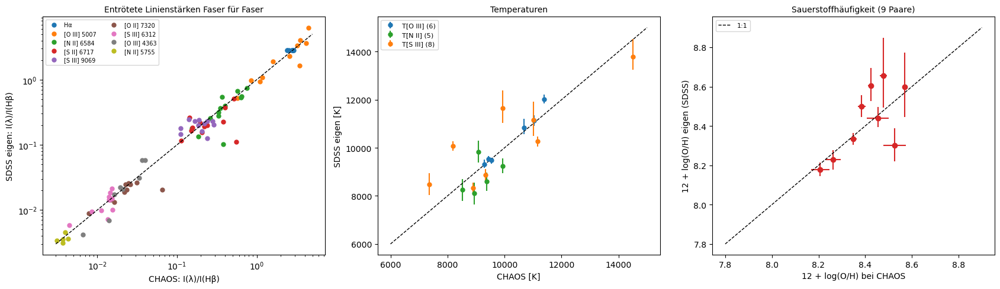

In [39]:
hii.fibers_vs_chaos()

**39. Der Gradient gegen CHAOS**

Derselbe Fit läuft über die 77 Regionen von CHAOS, zum Vergleich mit den 19 SDSS-Fasern.

CHAOS ergibt 8.71 − 0.81 · R/R25, die SDSS-Fasern 8.72 − 0.74 · R/R25: gleicher Achsenabschnitt, eine um 0.6σ flachere Steigung; bei 0.2, 0.5 und 0.8 Scheibenradien unterscheiden sich beide um höchstens 0.07 dex. Der Fehler der Steigung ist 3.5-mal so groß wie bei CHAOS, weil die SDSS-Fasern mit Temperatur nur von 0.2 bis 0.82 Scheibenradien reichen.

CHAOS, eigener Fit an die Tabelle (77 Regionen): 8.710 ± 0.023 -0.810 ± 0.046 R/R25, innere Streuung 0.081 dex
CHAOS im Paper: 8.716 ± 0.023 -0.832 ± 0.044 R/R25, innere Streuung 0.074 dex
SDSS eigen (19 Fasern): 8.717 ± 0.087 -0.742 ± 0.155 R/R25, innere Streuung 0.091 dex
  Achsenabschnitt: Unterschied +0.001 = +0.0 σ
  Steigung: Unterschied +0.090 = +0.6 σ
  bei R/R25 = 0.2: SDSS 8.57, CHAOS 8.55
  bei R/R25 = 0.5: SDSS 8.35, CHAOS 8.30
  bei R/R25 = 0.8: SDSS 8.12, CHAOS 8.05


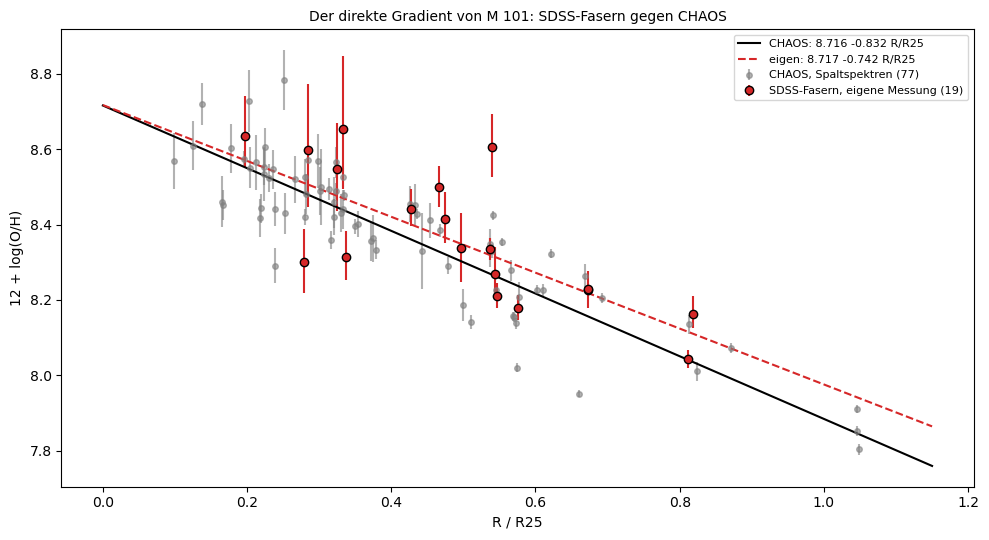

In [40]:
hii.gradient_vs_chaos()

**40. Starke Linien gegen die direkte Methode**

Wo die schwachen Linien fehlen, schätzt man den Sauerstoff aus starken Linien, mit empirischen Eichungen (Pettini und Pagel 2004, Marino et al. 2013) oder mit Photoionisationsmodellen (MPA-JHU-Katalog von SDSS). Verglichen wird Faser für Faser und als Gradient.

Gegenüber der direkten Methode liegen Pettini und Pagel 0.12 bis 0.13 dex zu tief, Marino et al. 0.15 bis 0.19 dex, MPA-JHU dagegen 0.44 dex zu hoch. Die empirischen Eichungen drängen die Werte auf 8.0 bis 8.5 zusammen, ihre Gradienten sind flacher (−0.40 bis −0.59 pro Scheibenradius), der von MPA-JHU steiler (−1.00). Die bekannte Differenz von 0.6 dex zwischen den Eichungen verteilt sich also auf beide Seiten, gemessen an der Temperatur.

42 Fasern mit Sternentstehung und allen vier starken Linien; 37 davon mit MPA-JHU-Wert
Eichung                            Paare  minus direkt  Streuung  Gradient [dex/R25]
N2, Pettini & Pagel (2004)            15        -0.115     0.142              -0.527
O3N2, Pettini & Pagel (2004)          15        -0.132     0.154              -0.591
N2, Marino et al. (2013)              15        -0.152     0.140              -0.427
O3N2, Marino et al. (2013)            15        -0.187     0.147              -0.395
MPA-JHU, Tremonti et al. (2004)       15        +0.437     0.137              -1.004
direkt (Schritt 37)                                                           -0.742


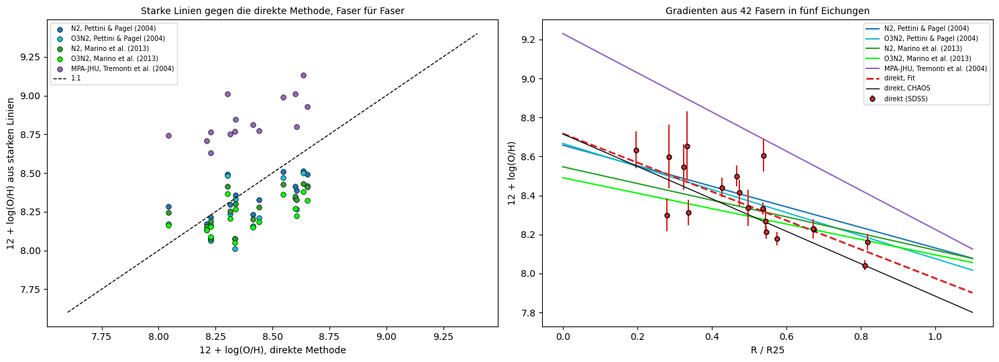

In [41]:
hii.strong_lines()

**41. Planetarische Nebel: Kataloge und Atomdaten**

Planetarische Nebel begleiten das Ende fast aller Sterne bis acht Sonnenmassen, vermutlich auch das der Sonne: Der Nebel ist die abgestoßene Hülle, der Stern in der Mitte der freigelegte Kern auf dem Weg zum Weißen Zwerg. Herschel nannte sie 1785 so, weil sie im Fernrohr wie Uranus aussahen. Geladen werden die Zentralsterne in Gaia (Chornay und Walton 2021), der Strasbourg-ESO-Katalog mit Linienstärken und Expansionsgeschwindigkeiten, Entwicklungswege der Zentralsterne, ein Katalog von Temperaturen aus der Literatur, zwei Kataloge von Nebeln in M 31 und Atomdaten für Wasserstoff und Helium.

Die Ausgabe zählt die Zeilen jedes Katalogs: 2117 Nebel mit Gaia-Kandidat, 1143 im Strasbourg-ESO-Katalog (614 mit Geschwindigkeiten), 618 Temperaturen aus der Literatur, 429 und 3300 Nebel in M 31. Dazu die Atomkonstanten (Hα/Hβ ohne Staub 2.863) und sechs Entwicklungswege; deren Leuchtkraft auf dem Plateau gibt über die Kern-Leuchtkraft-Beziehung die Kernmasse auf 0.01 bis 0.03 Sonnenmassen genau zurück.

In [42]:
planetary.load()

Chornay & Walton 2021       2117 Zeilen
Strasbourg-ESO: Nebel       1143 Zeilen
  mit Durchmesser           1138 Zeilen
  mit Hβ-Fluss               991 Zeilen
  mit Linienstärken         1045 Zeilen
  mit Geschwindigkeiten      614 Zeilen
  mit Zentralstern           692 Zeilen
Vassiliadis & Wood 1994      720 Zeilen
Weidmann et al. 2020         618 Zeilen
Ciardullo et al. 1989        429 Zeilen
Merrett et al. 2006         3300 Zeilen
k(λ) = A_λ/E(B−V): Hβ 3.61, Hα 2.54, 5007 3.47, 4686 3.79, V 3.11
Hα/Hβ ohne Staub = 2.863;  α_eff(Hβ)/α_B = 0.119;  α_eff(4686)/α_B(He⁺) = 0.236
Spuren bei Z = 0.016: Anfangsmassen [1.0, 1.5, 2.0, 2.5, 3.5, 5.0] M☉, Kernmassen [0.569, 0.597, 0.633, 0.677, 0.754, 0.9] M☉, 270 Punkte
  M_i = 1.0: Plateau log L = 3.56, Kernmasse aus L = 59250 (M_c − 0.495): 0.556 (Tabelle 0.569)
  M_i = 1.5: Plateau log L = 3.74, Kernmasse aus L = 59250 (M_c − 0.495): 0.588 (Tabelle 0.597)
  M_i = 2.0: Plateau log L = 3.89, Kernmasse aus L = 59250 (M_c − 0.495): 0.627 (Tab

**42. Vier Nebel im Bild**

Farbbilder aus Pan-STARRS (Filter g, r, i) von vier bekannten Nebeln, vom kleinen, hellen Blauen Schneeball NGC 7662 über den Ringnebel M 57 und den Hantelnebel M 27 zum großen, blassen Abell 39. Markiert sind der Zentralstern aus Gaia, der Radius des Nebels und ein Balken von 0.1 pc in der Gaia-Entfernung.

NGC 7662 hat 0.13 pc Radius, M 57 0.17 pc, M 27 und Abell 39 je 0.45 pc; wachsen alle gleich schnell, ist NGC 7662 der jüngste. Blau ist [O III], grün Hα und [N II]: In M 57 und M 27 sitzt das Blaue innen, wo das Gas nahe am Stern höher ionisiert ist. Im kleinen NGC 7662 geht der Zentralstern im Nebel fast unter, im großen Abell 39 ist er der hellste Punkt.

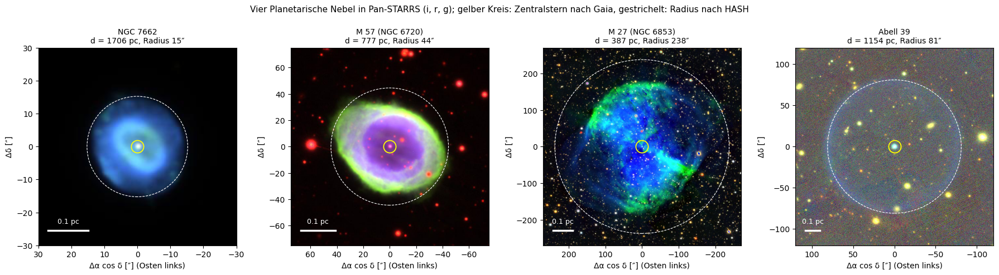

          Nebel        PNG     G  Parallaxe_mas    SN    d_pc  Radius_as  Radius_pc
       NGC 7662 106.5-17.6 13.93           0.57 17.04 1706.48      15.25       0.13
M 57 (NGC 6720) 063.1+13.9 15.65           1.27 29.01  777.24      44.50       0.17
M 27 (NGC 6853) 060.8-03.6 14.04           2.57 68.92  386.55     237.50       0.45
       Abell 39 047.0+42.4 15.57           0.85 20.14 1153.54      81.00       0.45


In [43]:
planetary.images()

**43. Kataloge und Auswahl**

Die Kataloge werden über die Bezeichnung der Nebel verknüpft. Die Arbeitsstichprobe sind Nebel mit sicher zugeordnetem Zentralstern und guter Parallaxe (Signal-Rausch über 5).

Von 2117 Nebeln mit Gaia-Kandidat haben 291 eine gute Parallaxe. Sie liegen nicht gleichmäßig: 83 % aller Nebel liegen nahe der Milchstraßenebene, aber nur 54 % der Arbeitsstichprobe, weil die Nebel in Bulge und Ebene zu weit und zu stark gerötet sind. Jeder spätere Schritt arbeitet mit einer kleineren Teilmenge: 112 haben einen Hβ-Fluss, 88 dazu die Helligkeit des Sterns, 47 die Linie He II 4686, 92 Radius und Expansionsgeschwindigkeit.

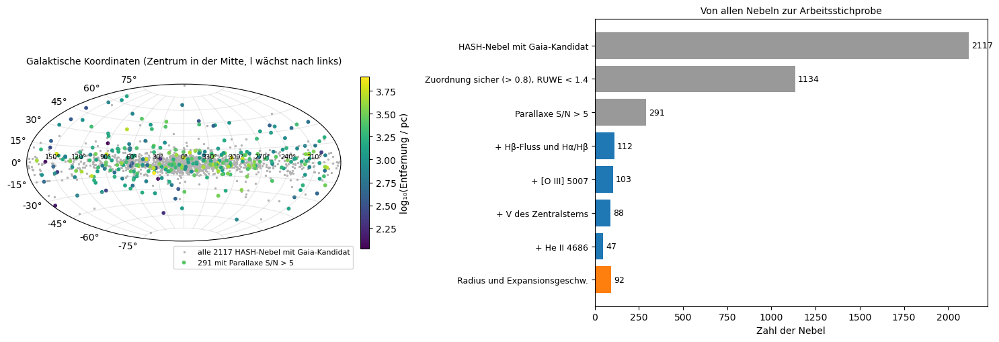

HASH-Nebel mit Gaia-Kandidat            2117
Zuordnung sicher (> 0.8), RUWE < 1.4    1134
Parallaxe S/N > 5                        291
+ Hβ-Fluss und Hα/Hβ                     112
+ [O III] 5007                           103
+ V des Zentralsterns                     88
+ He II 4686                              47
Radius und Expansionsgeschw.              92
Gesättigtes 5007 durch 2.98 × 4959 ersetzt: 30 Nebel im ganzen Katalog
Anteil mit |b| < 10°: alle 83%, Arbeitsstichprobe 54%


In [44]:
planetary.catalogs()

**44. Entfernungen aus Gaia**

Die Entfernung ist 1/Parallaxe nach Korrektur um den Nullpunkt von Gaia. Zum Vergleich dient die Entfernung von Chornay und Walton, die die Parallaxe mit einer statistischen Entfernung kombiniert.

Nur 291 von 1134 sicher zugeordneten Zentralsternen haben S/N über 5. Für sie stimmen beide Entfernungen im Median auf 5 %. Für S/N zwischen 2 und 5 ist 1/Parallaxe im Median 21 % kleiner: Wer nach S/N auswählt, nimmt bevorzugt Sterne, deren Parallaxe zufällig zu groß ist. Die Arbeitsstichprobe hat Entfernungen um 1574 pc; die nächsten sind große, alte Nebel wie WPS 28 in 106 pc mit fast einem Parsec Radius.

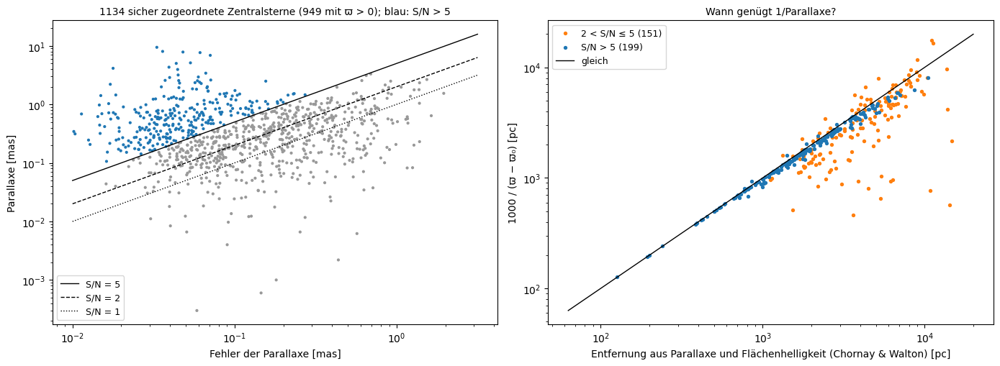

S/N > 5   :  291 Sterne, log10(1/ϖ ÷ kombiniert) Median -0.020, Anteil 1/ϖ größer: 5%, typischer Fehler der Entfernung 8%
2 < S/N ≤ 5:  262 Sterne, log10(1/ϖ ÷ kombiniert) Median -0.099, Anteil 1/ϖ größer: 21%, typischer Fehler der Entfernung 33%
Arbeitsstichprobe: 291 Nebel, Entfernung Median 1574 pc (10 % bis 90 %: 546 bis 3935 pc)
Die nächsten fünf: WPS 28 106 pc, FP J1912-0331 124 pc, Sh 2-216 127 pc, Fr 2-42 130 pc, Alves 3 145 pc


In [45]:
planetary.distances()

**45. Rötung aus dem Balmer-Dekrement**

Ohne Staub legt die Atomphysik Hα/Hβ auf 2.86 fest; Staub schwächt blaues Licht stärker, das Verhältnis wird größer. Aus dem Überschuss folgt die Rötung E(B−V), und damit werden Hβ, [O III], He II und die Helligkeit des Sterns korrigiert.

Die meisten der 116 Nebel haben Hα/Hβ zwischen 3 und 7. Die Rötung ist im Median 0.33 mag und hängt viel stärker an der galaktischen Breite als an der Entfernung: 0.74 nahe der Ebene, 0.13 hoch darüber, denn der Staub liegt in einer dünnen Schicht. Für die Zanstra-Methode heben sich die Korrekturen fast auf, für die [O III]-Helligkeit schlagen sie voll durch.

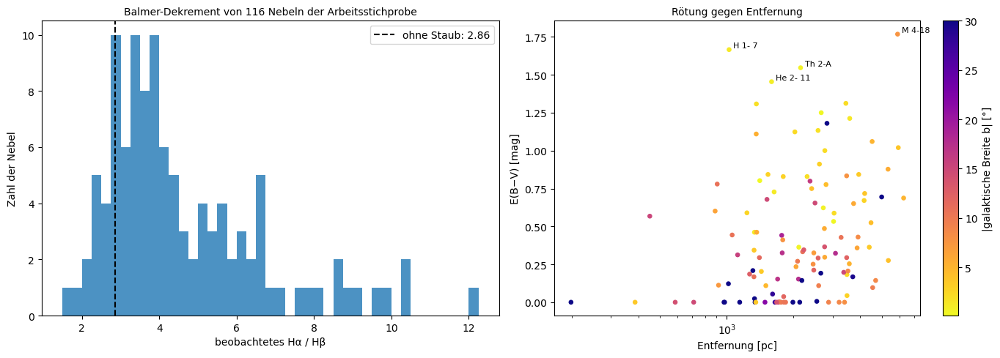

116 Nebel: E(B−V) Median 0.33 mag, c(Hβ) Median 0.47; 18% haben Hα/Hβ < 2.86 (E = 0 gesetzt)
E(B−V) Median: näher als 1.5 kpc 0.20 (31), weiter 0.36 (85); |b| < 5°: 0.74, |b| > 15°: 0.13
Schwächung bei E(B−V) = 1: Hβ 3.61 mag, [O III] 5007 3.47 mag, V 3.11 mag


In [46]:
planetary.reddening()

**46. Größe und kinematisches Alter**

Winkelradius mal Entfernung gibt den Radius, die Aufspaltung der Linie [O III] die Expansionsgeschwindigkeit (Vorder- und Rückseite der Hülle bewegen sich in entgegengesetzte Richtungen). Radius durch Geschwindigkeit ist das kinematische Alter.

Die Radien reichen von 0.07 bis 0.85 pc (Median 0.19 pc), die Geschwindigkeiten meist von 8 bis 45 km/s. Die 92 Alter haben einen Median von 9200 Jahren; ältere Nebel als etwa 50 000 Jahre sind so dünn, dass man sie nicht mehr sieht. Größere Nebel wachsen schneller, wie in Modellen, in denen der Wind des Sterns die Schale beschleunigt. NGC 7662 ist 4500 Jahre alt, M 27 29 000.

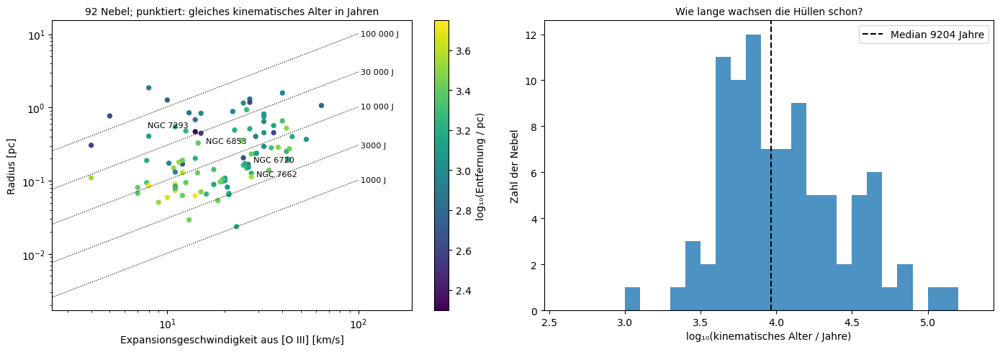

92 Nebel: Radius Median 0.192 pc (0.067 bis 0.846), Geschwindigkeit Median 19.8 km/s, Alter Median 9204 Jahre (10 % bis 90 %: 4369 bis 47055)
Rangkorrelation Radius–Geschwindigkeit: +0.37
                 d   pnRad   R_pc  ExpVel      t_kin
Name                                                
NGC 7662  1706.485   15.25  0.126    27.5   4485.705
NGC 6720   777.242   44.50  0.168    26.5   6186.738
NGC 6853   386.548  237.50  0.445    15.0  29011.293
NGC 7293   198.831  485.00  0.468    14.0  32650.414


In [47]:
planetary.ages()

**47. Die Zanstra-Temperatur aus Wasserstoff**

Den heißen Stern sieht man im UV kaum, aber der Nebel zählt seine Photonen: Jedes Photon über 13.6 eV ionisiert ein Wasserstoffatom, und jede Rekombination liefert mit fester Wahrscheinlichkeit ein Hβ-Photon (Zanstra 1927). Das Verhältnis von Hβ-Fluss zur sichtbaren Helligkeit des Sterns steigt steil mit der Temperatur; für einen Schwarzkörper passt genau eine. Sterne, deren sichtbares Licht ein kühler Begleiter liefert, sind ausgelassen.

Hantel- und Helixnebel haben 127 000 und 116 000 K, NGC 3242 56 000 K und der Katzenaugennebel 45 000 K. Alle 77 Temperaturen aus Wasserstoff haben einen Median von 35 000 K, kühl für Sterne, die einen sichtbaren Nebel ionisieren: ein Hinweis, dass viele Nebel Photonen entweichen lassen.

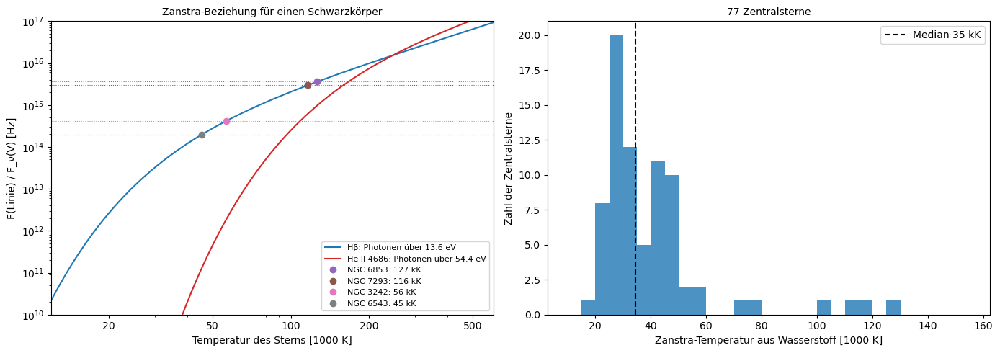

Zanstra-Temperatur (H) für 77 Sterne: Median 34507 K, 10 % bis 90 %: 24158 bis 53630 K
Ausgelassen wegen kühlem Begleiter: Me 1-1 (K1-2 II + ?), NGC 1514 (A0 + sdO), A 14 (A5 + ?), NGC 2346 (A5 IV + sdO), He 2- 36 (A2 III + sdO), SuWt 2 (A + A + ?)
          Vmag    EBV   V0     F_Hb      T_H
Name                                        
NGC 6853  13.9      0 13.9 3.47e-10 1.27e+05
NGC 7293  13.5      0 13.5 4.27e-10 1.16e+05
NGC 3242  12.3  0.209 11.7 3.25e-10 5.63e+04
NGC 6543  11.1 0.0233 11.1 2.65e-10 4.54e+04


In [48]:
planetary.zanstra_h()

**48. Ein zweites Thermometer: He II**

Dasselbe mit der Linie He II 4686, die die Photonen über 54.4 eV zählt. Ein großer, dünner Nebel lässt einen Teil der Photonen über 13.6 eV entweichen, dann wird die Wasserstoff-Temperatur zu niedrig; die selteneren Photonen über 54.4 eV werden meist vollständig geschluckt.

Für alle 39 Sterne liegt T(He II) über T(H), im Median 1.96-mal. Das Verhältnis wächst mit dem Radius des Nebels, von 1.64 unter 0.1 pc auf 2.21 darüber: Große, alte Nebel lassen mehr entweichen. Für die weiteren Schritte zählen 39 Temperaturen mit He II (Median 70 000 K) und 38 aus Wasserstoff als untere Grenzen.

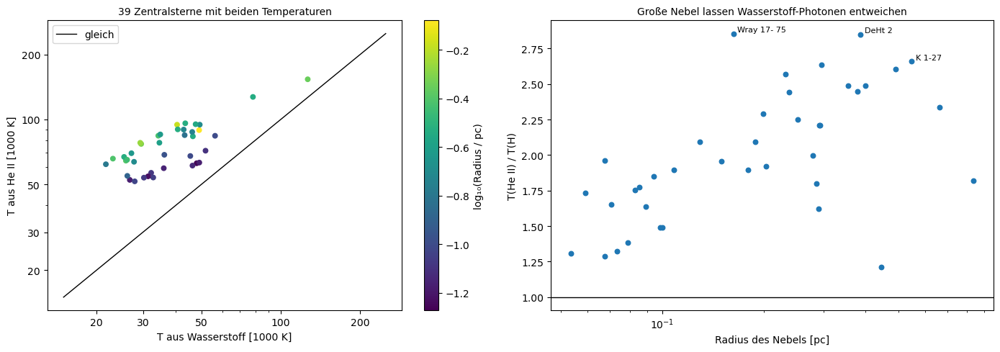

39 Sterne mit beiden Temperaturen: T(He II)/T(H) Median 1.96; Radius < 0.1 pc: 1.64 (12), ≥ 0.1 pc: 2.21 (27); Rangkorrelation mit dem Radius +0.61
Temperatur für die folgenden Schritte: 77 Sterne, davon 38 nur aus Wasserstoff (untere Grenze); Median mit He II 69719 K


In [49]:
planetary.zanstra_he()

**49. Das HR-Diagramm der Zentralsterne**

Mit Temperatur, entrötetter Helligkeit und Gaia-Entfernung folgt die Leuchtkraft. Dazu kommen die Entwicklungswege von Vassiliadis und Wood (1994) für Kernmassen von 0.57 bis 0.90 Sonnenmassen.

Die Sterne mit He-II-Temperatur liegen bei 50 000 bis 160 000 K entlang des waagrechten Asts und am Knie der leichten Spuren, viele unter der leichtesten. Die Leuchtkraft fällt mit dem Radius des Nebels: 5300 Sonnenleuchtkräfte bei kleinen Nebeln, 330 bei großen. Während der Nebel wächst, kühlt der Stern als werdender Weißer Zwerg ab.

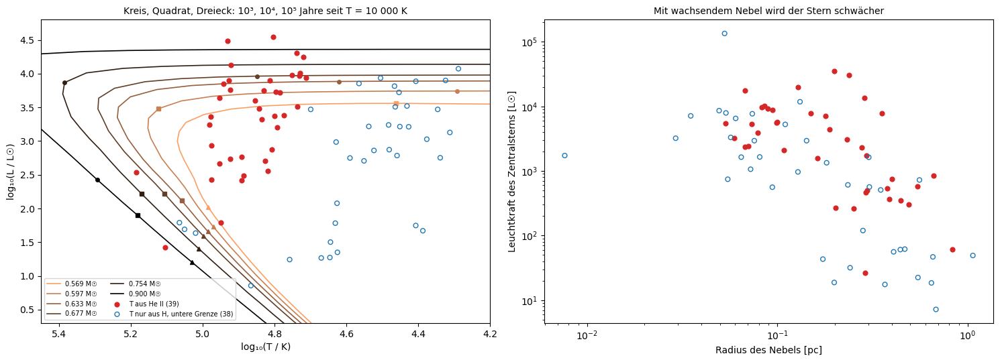

77 Sterne im HR-Diagramm; log L Median 3.48 (mit He II), 2.93 (nur H); Rangkorrelation Radius–Leuchtkraft -0.64
Radius < 0.1 pc: L Median 5288 L☉, > 0.3 pc: 327 L☉


In [50]:
planetary.hr_diagram()

**50. Kernmassen und zwei Uhren**

Aus den Entwicklungswegen folgen Kernmasse und Alter jedes Sterns. Das Alter auf dem Weg wird mit dem kinematischen Alter des Nebels verglichen: zwei unabhängige Uhren.

19 der 39 Sterne liegen unter der leichtesten Spur, 17 im Gitter mit Median 0.65 Sonnenmassen, passend zu den Weißen Zwergen mit 0.6. Für NGC 6543 und NGC 3242 passen die Uhren (4000 gegen 4900 Jahre), im Mittel ist das Alter auf dem Weg aber 9-mal kleiner, und je schwerer der Kern, desto größer die Lücke. Der Grund ist die steile Masseabhängigkeit: Ein Fehler von 0.25 dex in der Leuchtkraft verschiebt das Alter um mehr als eine Größenordnung.

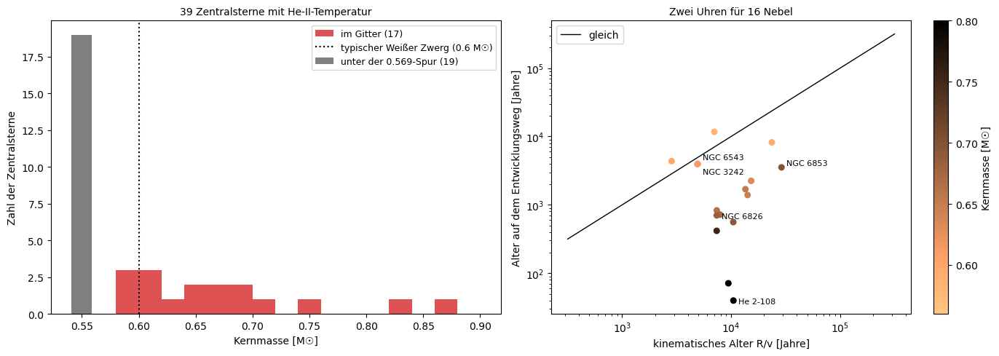

Kernmassen: 17 im Gitter, Median 0.652 M☉ (16 % bis 84 %: 0.600 bis 0.724); 19 von 39 unter der leichtesten Spur, 3 außerhalb des Gitters
Alter auf dem Weg ÷ kinematisch: Median 0.12, Streuung 0.73 dex; leichter als 0.6 M☉: 0.76 (2), schwerer: 0.11 (14)


In [51]:
planetary.core_masses()

**51. Die hellsten Nebel der Milchstraße in [O III]**

Die hellsten Planetarischen Nebel jeder Galaxie sind in [O III] 5007 fast gleich hell, die Grenze heißt M*, etwa −4.5 mag; das macht sie zu Entfernungsmessern. Geeicht wird mit den nahen Nebeln mit Gaia-Entfernung und mit den Nebeln des Bulge, die alle etwa 8.18 kpc entfernt stehen; wegen der starken Rötung zum Bulge zählen nur schwach gerötete.

Von den nahen Nebeln erreicht nur IC 1747 die Grenze, 103 sind zu wenige. Im Bulge erscheinen ohne Schnitt Nebel bis −7.6 mag, zwei bis drei Magnituden heller als irgendwo sonst: überkorrigierte Rötung und Vordergrundnebel. Mit dem Schnitt folgt M* = −4.72 (−4.97 bis −4.49) aus 35 Nebeln, verträglich mit dem Wert von Ciardullo (−4.53); je nach Umgang mit dem Staub schwankt er um ±0.15 mag.

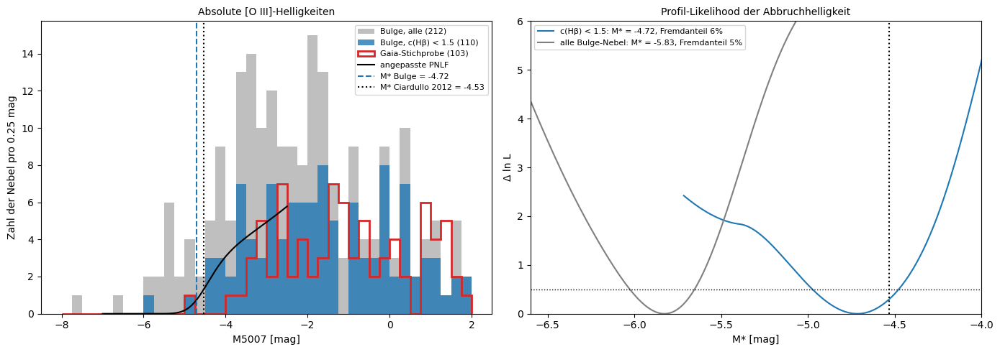

Hellste Nebel mit Gaia-Entfernung: IC 1747 -4.83, NGC 3242 -3.88, NGC 6153 -3.74, NGC 2867 -3.44, NGC 6567 -3.29
Bulge: 212 Nebel, c(Hβ) Median 1.47; mit c < 1.5: 110
Hellste Bulge-Nebel (alle): M 3-39 -7.64 (c = 3.5), Hb  4 -6.54 (c = 2.2), H 1-17 -5.82 (c = 2.8), NGC 6629 -5.75 (c = 1.0), M 1-35 -5.51 (c = 2.4)
Fit Bulge c < 1.5 : M* = -4.72 (1σ: -4.97 bis -4.49), Fremdanteil 5.8%, 35 Nebel heller als -2.5
Fit Bulge alle    : M* = -5.83 (1σ: -6.02 bis -5.66), Fremdanteil 5.5%, 97 Nebel heller als -2.5


In [52]:
planetary.brightest_oiii()

**52. Planetarische Nebel in M 31**

Zwei Kataloge der Andromedagalaxie: 429 Nebel mit sorgfältiger Photometrie im Bulge (Ciardullo et al. 1989) und 3305 Objekte aus einer Durchmusterung der ganzen Scheibe mit Geschwindigkeiten (Merrett et al. 2006).

Die 3126 Nebel von M 31 zeigen die Rotation der Scheibe: Der Nordosten entfernt sich, der Südwesten kommt auf uns zu. Die Zahl der Nebel steigt ab m5007 ≈ 20.0 steil an; fünf Objekte darüber sind Kandidaten für Fremdobjekte. 373 Nebel stehen in beiden Katalogen, mit im Median gleicher Helligkeit (0.000 mag) und 0.15 mag Streuung.

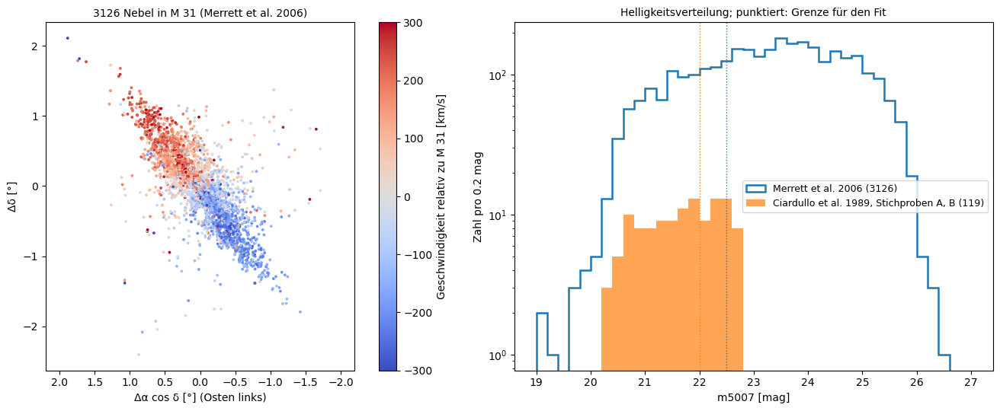

Merrett et al.: 3300 Objekte, davon 3126 in M 31; Begleiter und andere: NGC205 47, M32 46, NS 25, M32? 19, Stream? 18
Hellste fünf in M 31 (Merrett): [17.75 19.09 19.19 19.2  19.65] ; Ciardullo A/B: [20.28 20.31 20.32 20.43 20.49]
Gemeinsame Nebel: 373; Merrett − Ciardullo: Median +0.000 mag, robuste Streuung 0.148 mag
Geschwindigkeit: Nordosten (x > 0.5°) Median -106 km/s, Südwesten (x < −0.5°) -465 km/s


In [53]:
planetary.m31_nebulae()

**53. Die Leuchtkraftfunktion von M 31**

An beide Kataloge wird die Form der Leuchtkraftfunktion angepasst, mit Messfehler und einem kleinen Anteil Fremdobjekte; der Abbruch m* minus Staub minus M* gibt den Entfernungsmodul.

Ciardullo ergibt m* = 20.16 aus 76 Nebeln, Merrett 20.21 aus 919 Nebeln mit 2 % Fremdanteil; die Bereiche überlappen. Mit dem Staub der Milchstraße (0.2 mag) und M* = −4.53 folgen 791 und 809 kpc.

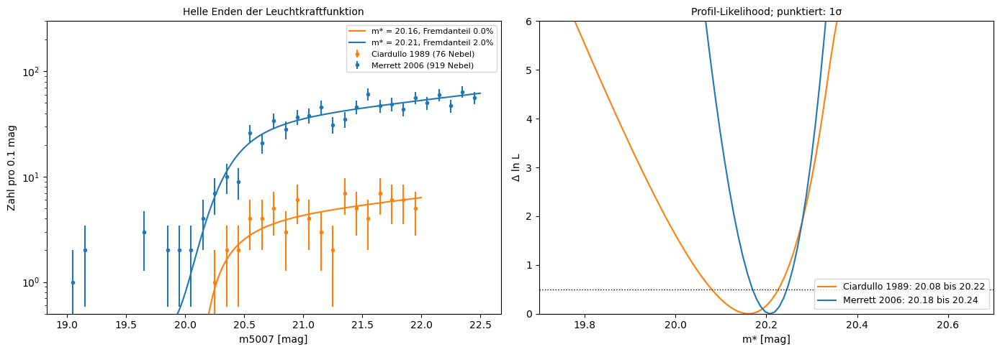

Vordergrund vor M 31: E(B−V) = 0.057, A5007 = 0.198 mag
Ciardullo 1989 : m* = 20.160 (+0.060 / −0.080), Fremdanteil 0.0% von 76; μ = 24.49 mit M* = -4.53, d = 791 kpc
Merrett 2006   : m* = 20.208 (+0.030 / −0.030), Fremdanteil 2.0% von 919; μ = 24.54 mit M* = -4.53, d = 809 kpc


In [54]:
planetary.luminosity_function()

**54. Temperaturen und Leuchtkräfte gegen die Literatur**

Weidmann et al. (2020) sammeln für jeden Zentralstern die beste Temperatur und Leuchtkraft aus der Literatur, meist aus Modellatmosphären an Spektren der Sterne.

Die Temperaturen mit He II liegen im Median nur 5 % unter der Literatur, die aus Wasserstoff 22 %, wie erwartet für untere Grenzen. Die größten Abweichungen haben Sterne mit wenig Wasserstoff (Th 2-A, Abell 30, Abell 43): Wo Wasserstoff fehlt oder der Nebel durchlässig ist, versagt die Methode. Die Leuchtkräfte streuen um fast 0.5 dex, auch weil die Literatur ältere Entfernungen ohne Gaia nutzt.

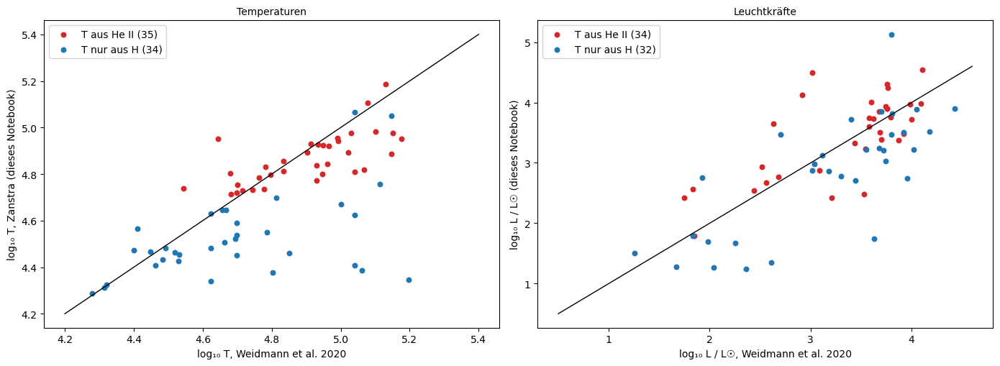

T aus He II :  35 Sterne, Δ log T Median -0.020, Streuung (robust) 0.076; Δ log L Median +0.10, Streuung 0.46
T nur aus H :  34 Sterne, Δ log T Median -0.106, Streuung (robust) 0.165; Δ log L Median -0.36, Streuung 0.50
Nur gegen Spektralanalysen („eff“) mit He-II-Temperatur: 22 Sterne, Δ log T Median -0.039
Größte Abweichungen: Th 2-A -0.85, A 30 -0.67, A 43 -0.63, Sa 1-8 -0.43


In [55]:
planetary.literature()

**55. Die Entfernung von M 31**

Die Entfernung aus den Nebeln neben drei unabhängigen Methoden: Cepheiden, Spitze des Roten Riesenasts und Bedeckungsveränderliche; einmal mit M* = −4.53 von Ciardullo und einmal mit der eigenen Eichung im Bulge.

Mit M* = −4.53 liegen die Nebel bei 24.49 und 24.54 mag, 0.9σ und 1.7σ über den Cepheiden (24.41): Planetarische Nebel treffen die Entfernung auf etwa 5 %. Mit der eigenen Eichung aus dem Bulge wird M 31 0.19 mag weiter (862 und 881 kpc). Der Wert von Ciardullo ist zum Teil an M 31 geeicht und damit nicht ganz unabhängig; die Bulge-Eichung ist unabhängig, aber nur so gut wie die Korrektur der Rötung.

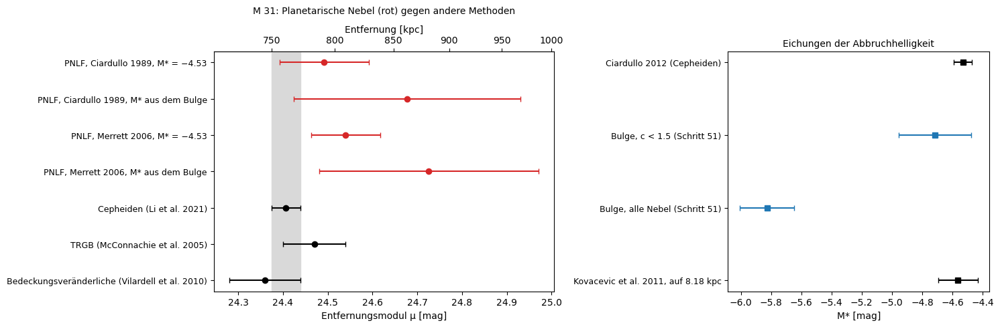

PNLF, Ciardullo 1989, M* = −4.53                 μ = 24.49 ± 0.10  d =  791 kpc
PNLF, Ciardullo 1989, M* aus dem Bulge           μ = 24.68 ± 0.25  d =  862 kpc
PNLF, Merrett 2006, M* = −4.53                   μ = 24.54 ± 0.08  d =  809 kpc
PNLF, Merrett 2006, M* aus dem Bulge             μ = 24.73 ± 0.24  d =  881 kpc
Cepheiden (Li et al. 2021)                       μ = 24.41 ± 0.03  d =  761 kpc
TRGB (McConnachie et al. 2005)                   μ = 24.47 ± 0.07  d =  783 kpc
Bedeckungsveränderliche (Vilardell et al. 2010)  μ = 24.36 ± 0.08  d =  745 kpc
Abstand zu den Cepheiden: Ciardullo 1989, M* = −4.53 +0.09 (+0.9σ), Ciardullo 1989, M* aus dem Bulge +0.27 (+1.1σ), Merrett 2006, M* = −4.53 +0.13 (+1.7σ), Merrett 2006, M* aus dem Bulge +0.32 (+1.3σ)
M* aus dem Bulge -4.72 ± 0.24 gegen Ciardullo -4.53 und Kovacevic -4.56


In [56]:
planetary.m31_distance()

**56. Krebsnebel: drei Bilder aus 60 Jahren und der Pulsar**

Im Juli 1054 sahen Astronomen am chinesischen Kaiserhof einen „Gaststern“ im Stier, 23 Tage lang auch am Tag. An derselben Stelle steht heute der Krebsnebel, Messier 1, mit einem Pulsar in der Mitte, der sich 30-mal pro Sekunde dreht. Rechnet man die heutigen Geschwindigkeiten der Filamente zurück, landet man nicht bei 1054, sondern einige Jahrzehnte später; die übliche Erklärung ist, dass der Wind des Pulsars die Filamente seither beschleunigt hat. Das wird hier nachgemessen, mit zwei Palomar-Platten (1951 und 1991), Pan-STARRS-Bildern (2009 bis 2014), Gaia-Sternen als Bezugssystem und den monatlichen Messungen des Pulsars aus Jodrell Bank seit 1982.

Die Ausgabe listet die geladenen Dateien im Cache: zwei Platten, vier Pan-STARRS-Bilder aus zwei Skycells mit ihren Kopfdaten, Gaia-Feld und Pulsar, die Ephemeriden aus Jodrell Bank.

In [57]:
crab.load()

Geladen: crab.txt, crab2.txt, gaia_field.csv, gaia_pulsar.csv, poss1_red.fits, poss2_red.fits, ps1_i_21.935.txt, ps1_i_22.015.txt, ps1_r_21.935.txt, ps1_r_22.015.txt, rings.v3.skycell.1784.049.stk.i.unconv.fits, rings.v3.skycell.1784.049.stk.r.unconv.fits, rings.v3.skycell.1784.059.stk.i.unconv.fits, rings.v3.skycell.1784.059.stk.r.unconv.fits


**57. Drei Fotos aus 60 Jahren**

Jedes Bild mit seiner Plattenlösung und seinem Datum, oben der ganze Ausschnitt von 12′, unten 80″ um ein helles Filament südlich des Pulsars.

Zwischen der ersten Platte (7. November 1951) und dem Pan-STARRS-Stapel (mittlere Epoche 2011.86) liegen 60.00 Jahre. 1951 ist das Innere des Nebels gesättigt und das Filament ein grober Streifen, 1991 ein klarer Strich, bei Pan-STARRS zerfällt es in Knoten. Wächst der Nebel seit 1054 gleichmäßig, wandert ein Filament 190″ vom Zentrum in 60 Jahren um etwa 12″, sieben Pixel der alten Platte.

Bild         Epoche   Pixel      Größe  Band und Belichtung
POSS-I E    1951.85   1.70″   424×424   103aE + rotes Plexiglas, 620–670 nm; Platte 070U, 50 min
POSS-II F   1991.80   1.01″   713×714   IIIaF + RG610, 610–690 nm; Platte A1YP, 65 min
PS1 r       2011.86   0.50″  1440×1440  CCD, Filter r, 550–690 nm; 16 Belichtungen, 720 s, 2009-12 bis 2014-03
PS1 i       2013.19   0.50″  1440×1440  CCD, Filter i, 690–820 nm; 22 Belichtungen, 990 s, 2010-11 bis 2014-12
PS1-Mosaik: Skycells im Überlapp angeglichen (Skala 1.003), Überlapp 17% des Ausschnitts
Zeitbasis 1951 -> PS1 r: 60.00 Jahre


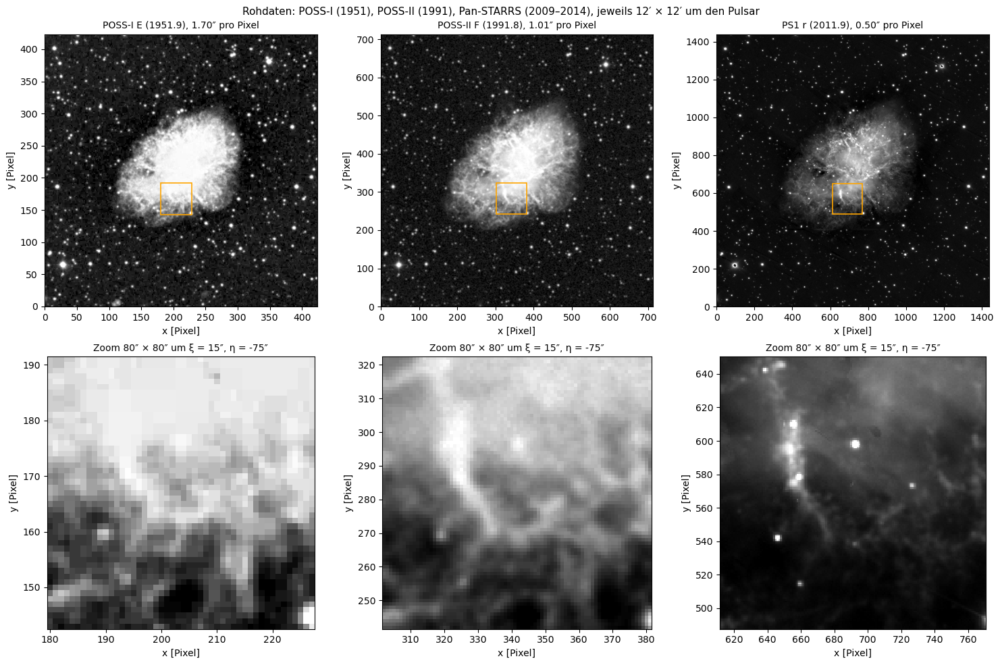

In [58]:
crab.photos()

**58. Filamente und Synchrotronlicht**

Der Filter i enthält keine helle Linie, dort leuchtet fast nur das Synchrotronlicht des Pulsarwindnebels. Im Filter r kommen Hα, [N II], [S II] und [O I] der Filamente dazu. Zieht man vom r-Bild das skalierte i-Bild ab, bleibt das Linienlicht.

Der Faktor 0.62 passt zu einem Synchrotronspektrum mit Rötung, das im Filter i heller ist. Das i-Bild zeigt eine glatte, wolkige Fläche, das Differenzbild nur das Netz der Filamente, dicht im Norden. Ein Drittel des r-Lichts kommt aus Linien. Dunkle Flecken am Pulsar sind vermutlich Strukturen, die sich mit halber Lichtgeschwindigkeit bewegen und zwischen den Belichtungen gewandert sind.

Synchrotron mit alpha = 0.6: r/i = 0.889 ohne Staub, 0.671 mit E(B-V) = 0.52
Synchrotron mit alpha = 0.8: r/i = 0.855 ohne Staub, 0.645 mit E(B-V) = 0.52
Synchrotron mit alpha = 1.0: r/i = 0.823 ohne Staub, 0.620 mit E(B-V) = 0.52
gemessen: k = 5. Perzentil von r/i im Inneren (ohne Sterne) = 0.618 -> Spektralindex alpha = 1.02 (mit Rötung); mit dem 10. Perzentil 0.643 -> alpha = 0.81
Anteil des Linienlichts am r-Licht des Feldes: 32%


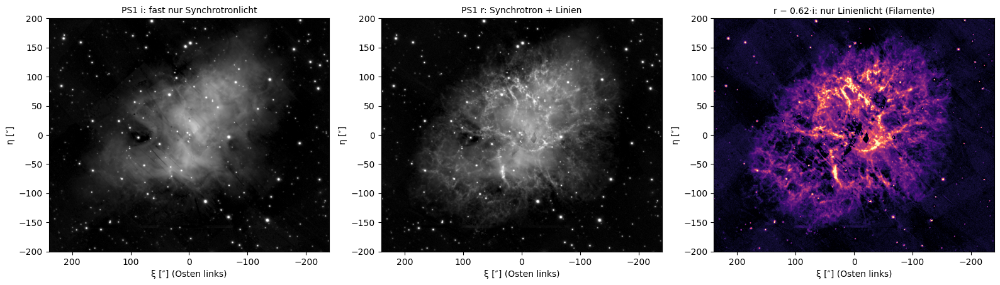

In [59]:
crab.filaments()

**59. Gaia-Sterne als Bezugssystem**

Jede Platte hat ihre eigene Verzerrung. Gaia gibt für jeden Stern Ort und Eigenbewegung; auf das Datum der Platte zurückgeschoben, liefern die Sterne ein Gitter von Bezugspunkten.

Im Feld liegen 1171 Gaia-Sterne; im Median wandern sie in 60 Jahren 0.14″, 30- bis 100-mal weniger als ein Filament, aber so viel wie der Restfehler einer Platte, deshalb zählt die Korrektur. Der Pulsar selbst ist ein Gaia-Stern (G = 16.5) und läuft nach Westnordwest; 1054 stand er 11″ östlich seines heutigen Orts.

Gaia DR3 im Kreis von 7.5′: 1171 Sterne mit G < 20, davon 765 mit G < 19 und Eigenbewegung
Eigenbewegung: Median 2.4 mas/Jahr, also 0.14″ in 60 Jahren; 75 Sterne wandern mehr als 0.5″, der schnellste 14.7″
Pulsar (Gaia DR3 3403818172572314624): G = 16.53, Ort 2016.0 bei ξ = -0.07″, η = -0.01″, μ = (-11.51 ± 0.10, 2.30 ± 0.06) mas/Jahr, Parallaxe 0.511 ± 0.079 mas, RUWE 1.03
Pulsar mit seiner Eigenbewegung zurückgerechnet auf 1054: ξ = +11.0″, η = -2.2″


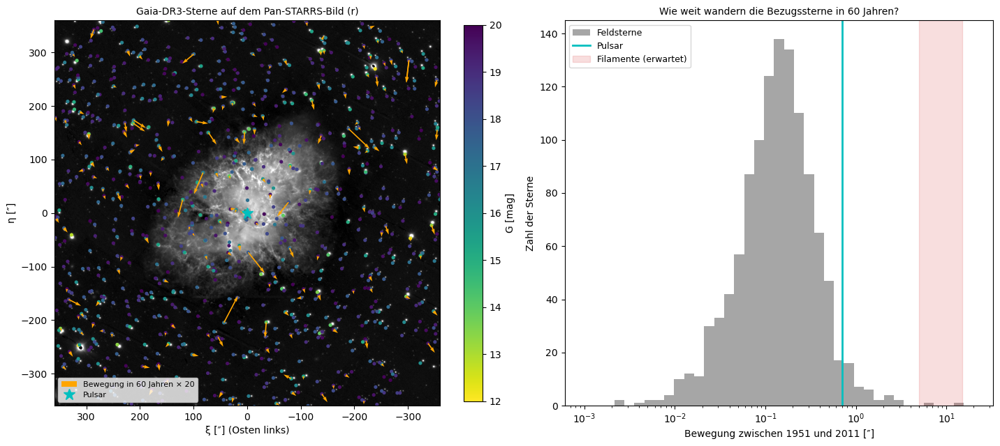

In [60]:
crab.gaia_frame()

**60. Astrometrie jeder Epoche**

In jedem Bild werden die Sterne gesucht, mit Gaia gepaart, und ein Polynom zweiten Grades bildet Pixel auf den Himmel ab. Sterne nahe am hellen Nebel bleiben draußen.

Die Plattenlösung im Kopf der Platte von 1951 liegt im Mittel 0.8″ daneben; die eigene Lösung bringt den Versatz auf null und die Streuung auf 0.19″. Für 1991 sind es 0.12″, für Pan-STARRS 0.02″. Die Abweichungen zeigen in zufällige Richtungen, und ein Polynom dritten Grades bringt kaum etwas: Auf 12′ ist die Platte praktisch unverzerrt.

POSS-I E  :  503 Sterne gefunden, 238 mit Gaia gepaart und benutzt; Kopf-Plattenlösung: Versatz (+0.79, +0.22)″, Streuung 0.22″ -> eigene Lösung: Rest 0.189″
POSS-II F :  703 Sterne gefunden, 277 mit Gaia gepaart und benutzt; Kopf-Plattenlösung: Versatz (+0.23, -0.16)″, Streuung 0.13″ -> eigene Lösung: Rest 0.124″


PS1 r     : 2152 Sterne gefunden, 319 mit Gaia gepaart und benutzt; Kopf-Plattenlösung: Versatz (-0.16, +0.14)″, Streuung 0.03″ -> eigene Lösung: Rest 0.018″


PS1 i     : 1710 Sterne gefunden, 317 mit Gaia gepaart und benutzt; Kopf-Plattenlösung: Versatz (-0.16, +0.14)″, Streuung 0.02″ -> eigene Lösung: Rest 0.011″
Kontrolle POSS-I E mit Polynom vom Grad 1: Rest 0.191″ (238 Sterne)
Kontrolle POSS-I E mit Polynom vom Grad 3: Rest 0.187″ (238 Sterne)


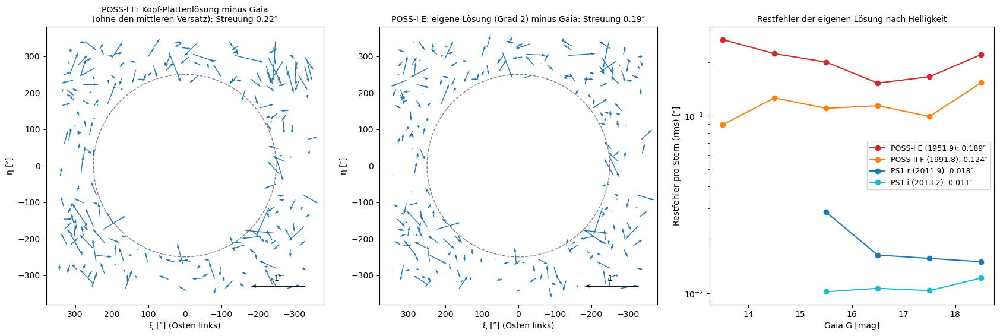

In [61]:
crab.epoch_astrometry()

**61. Gemeinsames Raster und die Expansion auf einen Blick**

Alle Bilder werden auf ein gemeinsames Raster von 1″ pro Pixel umgerechnet, auf dieselbe Schärfe geglättet, mit einem Hochpass von großräumigem Licht befreit, und die Sterne maskiert. Als erste Probe wird das Bild von 1951 schrittweise vergrößert und mit dem von 2011 verglichen.

Übereinandergelegt liegen die Fäden von 1951 (rot) und 2011 (türkis) nebeneinander. Vergrößert man das alte Bild um 6.9 %, decken sie sich, dafür stehen die Sterne doppelt. Gleichmäßiges Wachstum seit 1054 gäbe 6.7 %; dieses grobe Maß spricht für ein Startjahr um 1080.

POSS-I E  : Sterne im Raster mit FWHM 4.17″ (Median aus 169 Sternen) -> Glättungskern 1.42″


POSS-II F : Sterne im Raster mit FWHM 3.66″ (Median aus 171 Sternen) -> Glättungskern 2.45″


PS1 r     : Sterne im Raster mit FWHM 1.82″ (Median aus 170 Sternen) -> Glättungskern 4.01″


PS1 i     : Sterne im Raster mit FWHM 1.84″ (Median aus 170 Sternen) -> Glättungskern 4.00″
Nebelmaske: 82774 Quadratbogensekunden, so groß wie ein Kreis mit 162″ Radius; Sterne maskiert: 11% des Rasters


Korrelation 1951 gegen 2011: 0.18 ohne Vergrößerung, 0.40 bei s = 1.0688 (der Nebel ist um 6.9 % gewachsen) -> grobes Konvergenzjahr 1080
Erwartung bei konstanter Geschwindigkeit seit 1054: s = 1.0669 (6.7 %)


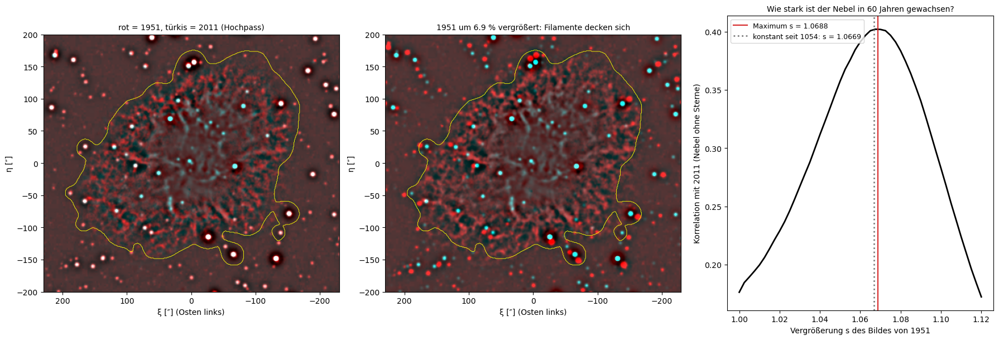

In [62]:
crab.common_grid()

**62. Wie weit sind die Filamente gewandert?**

Das Raster wird mit Ausschnitten von 21″ belegt; für jeden sucht die Kreuzkorrelation im Bild von 1951 die Stelle, die am besten passt. Ausschnitte mit schwacher Korrelation fallen weg.

847 Ausschnitte bleiben; im Median haben sie sich um 8.1″ verschoben, 86 % zeigen vom Pulsar weg. Die Pfeile laufen radial nach außen und werden nach außen länger, das Muster einer Expansion. Am Rand sind die Treffer am sichersten, weil dort scharfe Filamente vor dunklem Grund liegen; im glatten Inneren zeigen einige Pfeile in falsche Richtungen.

Ausschnitte in der Nebelmaske mit Maximum im Suchbereich: 1096; mit Korrelation > 0.6: 847
Verschiebung 1951 -> 2011 (60.00 Jahre): Median 8.12″, größte 26.4″; radial im Median +7.18″, tangential -0.06″
Anteil der Verschiebungen, die vom Pulsar weg zeigen: 86%
Beispiel bei ξ = -166″, η = 62″ (Abstand 177″): Verschiebung (-12.05, +3.99)″, Korrelation 0.89


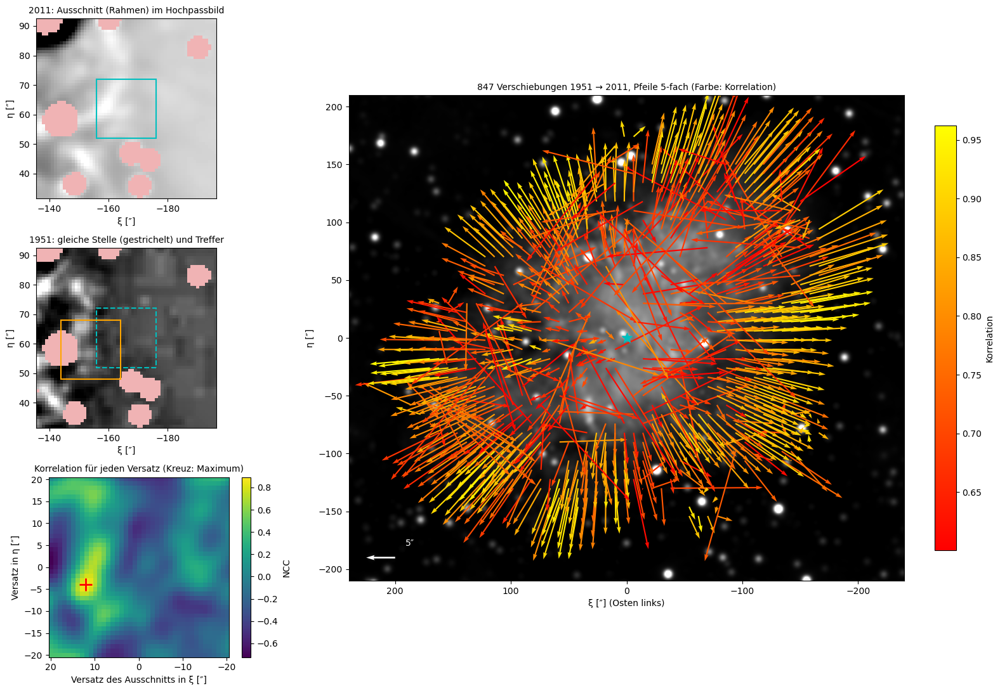

In [63]:
crab.displacements()

**63. Das Expansionszentrum und der Geburtsort des Pulsars**

Wächst der Nebel gleichmäßig, ist jede Verschiebung proportional zum Abstand vom Zentrum. Das ist ein lineares Problem mit drei Unbekannten (Faktor und zwei Koordinaten des Zentrums); die Unsicherheit kommt aus dem Bootstrap.

Das Zentrum liegt 10.3″ östlich des heutigen Pulsars. Der Pulsar stand 1054 nach Gaia nur 1.0″ davon entfernt: Er wurde am Ort der Explosion geboren und läuft seither mit etwa 110 km/s weg. Martin et al. (2025) finden aus fast 20 000 Verschiebungen dasselbe in Ost-West-Richtung und 3.5″ weiter südlich.

Expansionszentrum (eigene Messung): ξ = +10.0 ± 0.4″, η = -2.0 ± 0.5″ (630 von 847 Ausschnitten)
Pulsar 2016.0: ξ = -0.07″, η = -0.01″; zurückgerechnet auf 1054: ξ = +11.0″, η = -2.2″
Abstand Zentrum - Pulsar 1054: 1.0″ (Δξ = -1.0″, Δη = +0.2″); Zentrum - Pulsar heute: 10.3″
Martin et al. (2025): ξ = +10.2″, η = -5.5″ ± 1.2″; Unterschied zur eigenen Messung Δξ = -0.1″, Δη = +3.5″
Restabweichung pro Ausschnitt nach der Anpassung: 0.61″ pro Achse


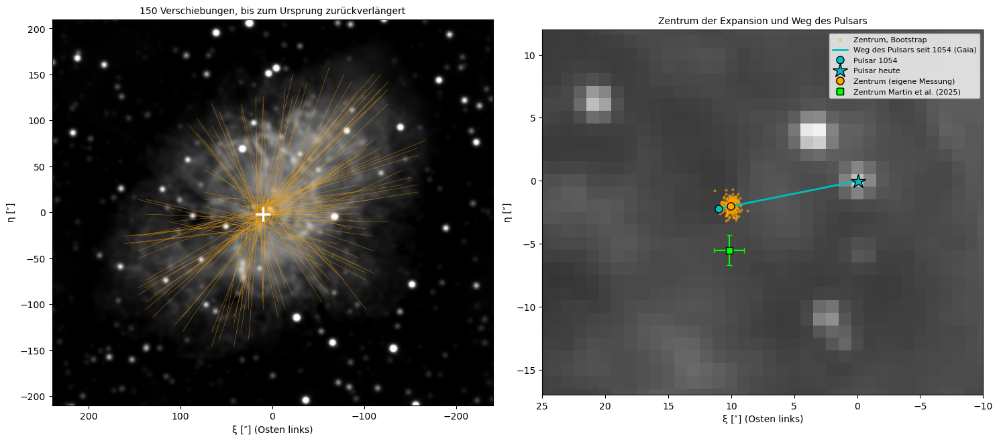

In [64]:
crab.expansion_center()

**64. Ein Hubble-Diagramm des Nebels und das Konvergenzjahr**

Die Geschwindigkeit vom Zentrum weg gegen den Abstand liegt bei gleichmäßigem Wachstum auf einer Geraden durch den Ursprung, wie im Hubble-Diagramm der Galaxien. Ihr Kehrwert ist das scheinbare Alter; das Jahr, in dem alles in einem Punkt war, heißt Konvergenzjahr. Zum Vergleich die ältere Methode: das Jahr, in dem die zurückgerechnete Punktwolke am kleinsten war.

Die Gerade gibt 1098.5 ± 2.9, gut 40 Jahre nach 1054: Die Filamente sind heute schneller als im Mittel seit der Explosion. Die ältere Methode findet 1109, und eine Simulation zeigt warum: Rauschen in den Geschwindigkeiten verschiebt ihr Minimum um 10 Jahre nach hinten. Das erklärt einen Teil der späten Jahre in der Literatur.

Steigung im Hubble-Diagramm: e = 0.1095 % pro Jahr -> scheinbares Alter 1/e = 913 Jahre vor 2011.9, Konvergenzjahr 1098.5 ± 2.9
Größte Geschwindigkeit am Himmel: 0.229″/Jahr in 200″ Abstand


Methode der kleinsten Streuung: Minimum 1109 (Radius dort 13.1″)
Simulation ohne Rauschen: Minimum 1098; mit 0.61″ Rauschen pro Achse: 1109 ± 3 (50 Ziehungen) -> Verschiebung um +10 Jahre


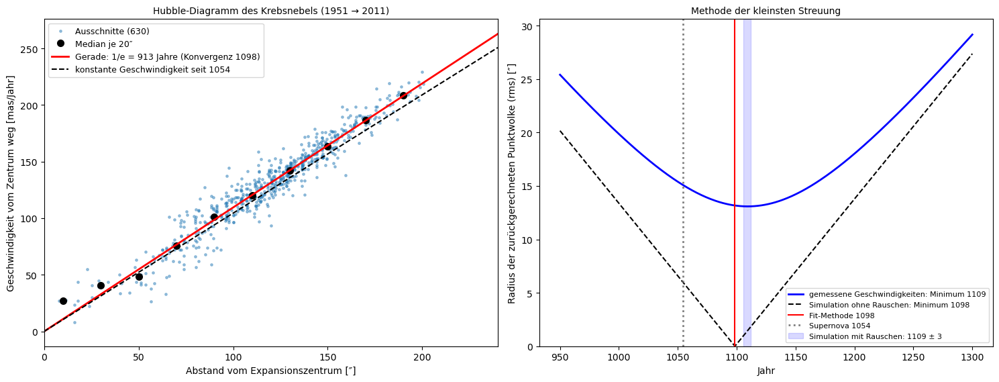

In [65]:
crab.hubble_diagram()

**65. Drei Epochen, drei Paare: Wie sicher ist das Jahr?**

Dieselbe Messung für die Paare 1951 → 1991 und 1991 → 2011, und das lange Paar mit geänderten Einstellungen (größere Ausschnitte, anderer Hochpass, größere Sternmasken). Die Streuung zeigt den systematischen Fehler, den der Bootstrap nicht sieht.

Die Paare mit 1951 geben 1098 und 1097, das kurze Paar 1113. Das kurze Paar ist dreimal empfindlicher: Ein Fehler von 0.1″ verschiebt das Jahr bei 20 Jahren Zeitbasis um 35 Jahre, bei 60 Jahren um 12. Mit den Einstellungen schwankt das Jahr um ±4 Jahre; das Ergebnis ist 1098 ± 3 (statistisch) ± 4 (systematisch).

1951 → 2011: Δt = 60.00 Jahre,  630 Ausschnitte, k = 0.06570, Konvergenzjahr  1098.5 ±  2.9, Zentrum (+10.0, -2.0)″
1951 → 1991: Δt = 39.95 Jahre,  923 Ausschnitte, k = 0.04466, Konvergenzjahr  1097.3 ±  3.1, Zentrum (+9.0, -2.6)″
1991 → 2011: Δt = 20.06 Jahre,  961 Ausschnitte, k = 0.02232, Konvergenzjahr  1113.2 ±  5.3, Zentrum (+10.2, -2.3)″
Verkettet: k = 0.06598 gegen direkt 0.06570 (Unterschied +0.4 %)


  Grundeinstellung           :  630 Ausschnitte, Konvergenzjahr  1098.5
  Ausschnitte 29″ statt 21″  :  651 Ausschnitte, Konvergenzjahr  1090.7
  Hochpass 4″ statt 6″       :  610 Ausschnitte, Konvergenzjahr  1097.3
  Hochpass 10″               :  688 Ausschnitte, Konvergenzjahr  1096.8
  Schärfe 5.5″ statt 4.4″    :  700 Ausschnitte, Konvergenzjahr  1094.8
  Sternmasken × 1.5          :  442 Ausschnitte, Konvergenzjahr  1088.0
  Korrelation > 0.75         :  422 Ausschnitte, Konvergenzjahr  1099.1
  Korrelation > 0.45         :  725 Ausschnitte, Konvergenzjahr  1096.7
Streuung über die Einstellungen (systematisch): ± 3.7 Jahre; Spanne 1088 bis 1099
Ergebnis: Konvergenzjahr 1098 ± 3 (statistisch) ± 4 (systematisch)


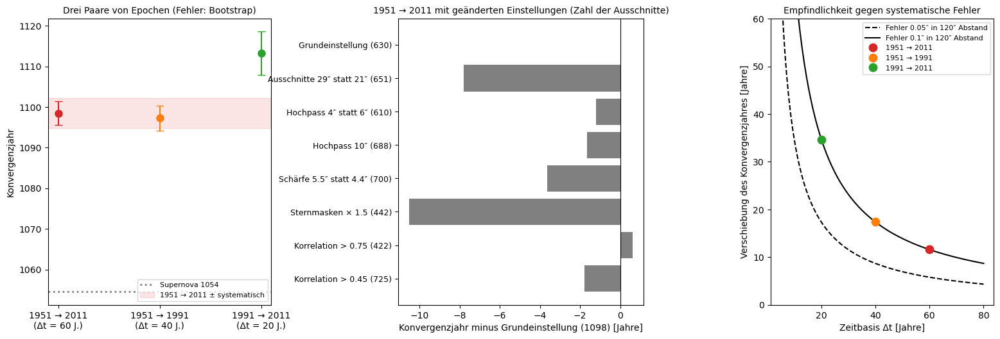

In [66]:
crab.three_epochs()

**66. Wie weit ist der Krebsnebel entfernt?**

Am Himmel misst man Bogensekunden pro Jahr, im Spektrum km/s; beide gehören über die Entfernung zusammen (Expansionsparallaxe). Die schnellsten Filamente bewegen sich mit etwa 1500 km/s entlang der Sichtlinie; ist der Nebel in der Tiefe so groß wie seine kurze Achse, folgt die Entfernung. Dagegen steht die Parallaxe des Pulsars aus Gaia und aus Radio-Interferometrie (VLBI).

Die Expansionsparallaxe ergibt 2003 ± 283 pc, Gaia 1957 pc, VLBI 1887 pc; alle drei überlappen. Bei 1957 pc ist der Nebel 3.6 × 2.7 pc groß, und die Filamente am Rand der kurzen Achse bewegen sich mit 1465 km/s quer zur Sichtlinie, so schnell wie entlang: Der Nebel ist in der Tiefe so groß wie seine kurze Achse.

Nebelmaske als Ellipse: halbe Achsen a = 190″, b = 144″, Lagewinkel 125°
Expansionsrate e = 1.095e-03 pro Jahr -> Rand der kurzen Achse bewegt sich mit 158 mas/Jahr
Expansionsparallaxe: d = 1500 km/s / (4.74 × 0.1580″/Jahr) = 2003 ± 283 pc
Gaia DR3: Parallaxe 0.511 ± 0.079 mas -> d = 1/ϖ = 1957 pc (68 %: 1695 bis 2313 pc)
VLBI (Lin et al. 2023): 0.53 ± 0.06 mas -> 1887 pc
Mit d = 1957 pc: Rand der langen Achse 1932 km/s, der kurzen 1465 km/s; Größe des Nebels 3.6 × 2.7 pc


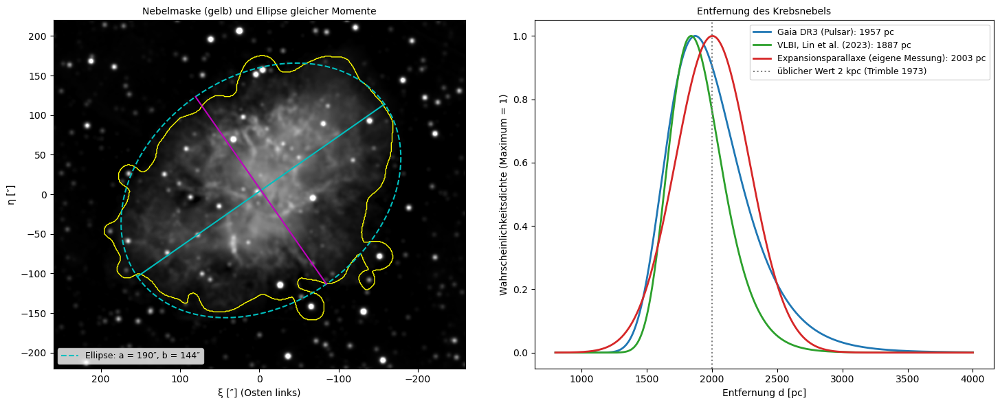

In [67]:
crab.distance()

**67. Der Pulsar bremst**

Die Ephemeriden von Jodrell Bank geben für jeden Monat seit 1982 die Rotationsfrequenz und ihre Ableitung. Daraus folgen die Leistung, die der Pulsar an Rotationsenergie verliert, sein Magnetfeld und das charakteristische Alter. Sprünge der Frequenz (Glitches) zeigen sich als Monate, in denen die Frequenz über dem aus dem Vormonat erwarteten Wert liegt.

In 44.6 Jahren ist der Pulsar von 30.06 auf 29.53 Umdrehungen pro Sekunde langsamer geworden. Er verliert 4.3·10³⁸ erg/s, gut 100 000 Sonnenleuchtkräfte; sein Magnetfeld ist 3.8·10¹² G. Das charakteristische Alter ist 1279 Jahre statt der wahren 972. Zehn Glitches liegen über der Schwelle, der größte 2017.

559 Monatswerte von 1982-02-15 bis 2026-09-15; Fehler typisch 2e-10 Hz in ν und 5e-16 Hz/s in ν̇
ν: 30.059224 Hz -> 29.534080 Hz (Verlust 0.5251 Hz in 44.6 Jahren)
Heute: P = 33.8592 ms, Ṗ = 4.194e-13 s/s, die Periode wächst also um 36 Nanosekunden pro Tag
Ė = 4π² I ν |ν̇| = 4.26e+38 erg/s = 1.1e+05 Sonnenleuchtkräfte (I = 1e+45 g cm²)
charakteristisches Alter τ_c = ν / (2|ν̇|) = 1279 Jahre (wahres Alter 972 Jahre); B = 3.81e+12 G
Glitches (Sprung > 1e-7 Hz): 10, in den Jahren 1989.7, 1996.5, 2000.6, 2001.5, 2004.2, 2004.7, 2006.7, 2011.9, 2017.9, 2019.6
größter Sprung: 14.7 µHz (Δν/ν = 5.0e-07) im Jahr 2017.9


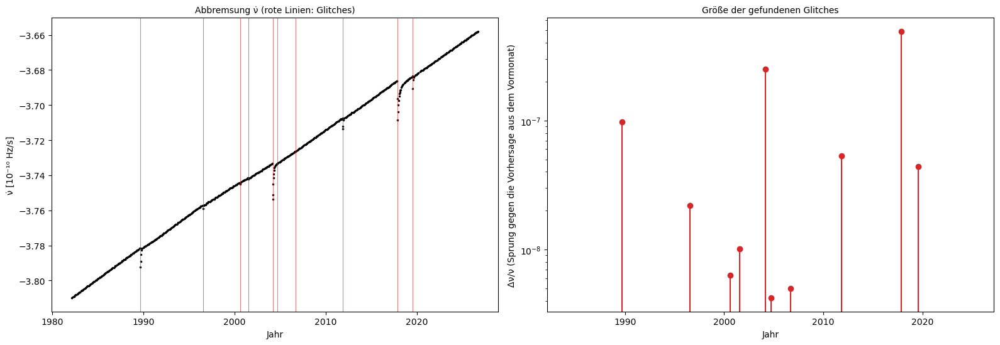

In [68]:
crab.pulsar()

**68. Bremsindex und Anfangsperiode**

Ein rotierender Magnet im Vakuum bremst mit dem Bremsindex 3. Der Index wird zwischen je zwei Glitches gemessen. Mit ihm und dem bekannten Alter folgt, wie schnell der Pulsar 1054 rotierte und wie viel Energie er seither abgegeben hat.

Der Index liegt im Median bei 2.51, wie bei Lyne et al. (2015), also unter 3; zwischen 1997 und 2004, als es viele Glitches gab, bei 2.22. Bei der Geburt drehte sich der Pulsar mit 19.3 ms Periode etwa 52-mal pro Sekunde, und seit 1054 hat er 3.6·10⁴⁹ erg Rotationsenergie abgegeben.

 start    end  n_pts    nuddot     n  n_err
1982.1 1989.6     91 1.201e-20 2.502  0.003
1990.1 1996.5     77 1.195e-20 2.517  0.005
1997.0 2000.5     44 1.049e-20 2.227  0.012
2002.0 2004.1     27 1.040e-20 2.220  0.015
2005.1 2006.6     19 1.122e-20 2.403  0.028
2007.1 2011.8     59 1.169e-20 2.517  0.005
2012.3 2017.8     69 1.175e-20 2.551  0.005
2020.0 2026.6     83 1.155e-20 2.537  0.003
Bremsindex zwischen Glitches: Median 2.51 (Abschnitte 2.22 bis 2.55); über alle 45 Jahre mit Glitches: 2.25
n = 2.51: Anfangsperiode P0 = 19.3 ms (52 Umdrehungen pro Sekunde), seit 1054 abgegebene Rotationsenergie 3.60e+49 erg
n = 2.25: Anfangsperiode P0 = 20.2 ms (49 Umdrehungen pro Sekunde), seit 1054 abgegebene Rotationsenergie 3.11e+49 erg
n = 3.00: Anfangsperiode P0 = 16.6 ms (60 Umdrehungen pro Sekunde), seit 1054 abgegebene Rotationsenergie 5.45e+49 erg


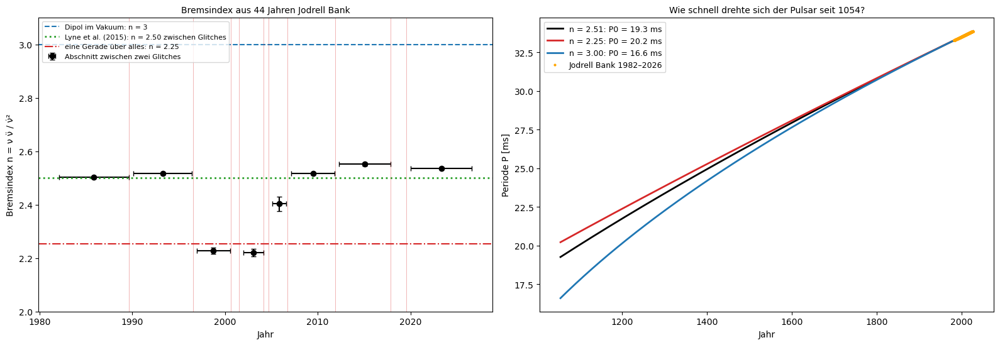

In [69]:
crab.braking_index()

**69. Das Konvergenzjahr gegen die Literatur**

Die eigene Messung neben neun veröffentlichten Werten seit 1939, von Fotoplatten bis zu CFHT-Bildern. Aus dem Konvergenzjahr folgt, um wie viel die Filamente schneller geworden sind.

Die Filamente sind heute 5.0 ± 0.6 % schneller als im Mittel seit 1054. Werte mit der Methode der kleinsten Streuung liegen in der Literatur systematisch später als Fits. Die eigene Messung (1098) liegt zwischen Bietenholz und Nugent (1091) und Martin et al. (1105.5); jedes Prozent Beschleunigung verlegt das Jahr um etwa 9 Jahre, die Unterschiede sind also nur 1 bis 2 Prozent.

                      Quelle   Jahr Fehler                 Methode
               Duncan (1939)   1172      –       kleinste Streuung
              Trimble (1968)   1140     15       kleinste Streuung
     Wyckoff & Murray (1977)   1120      7   Fit an Trimbles Daten
               Nugent (1998)   1130     16       kleinste Streuung
Rudie et al. (2008), nur Jet   1055     24                     Fit
  Bietenholz & Nugent (2015)   1091     34 Bayes, Daten von Nugent
        Martin et al. (2025) 1140.5    1.4       kleinste Streuung
        Martin et al. (2025) 1105.5    0.5                     Fit
              eigene Messung   1109      –       kleinste Streuung
              eigene Messung   1098      5                     Fit
Beschleunigung: β = 1.050 ± 0.006; die Filamente sind heute 5.0 % schneller als im Mittel seit 1054
Zum Vergleich: Bietenholz & Nugent (2015) β = 1.040 ± 0.039; Martin et al. (2025) v/v_h = 1.06 (eigene Messung im selben Maß: 1.048)


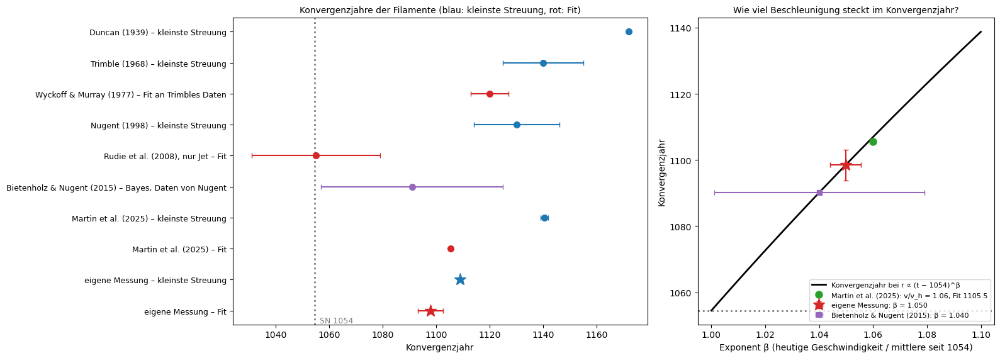

In [70]:
crab.literature()

**70. Energiebilanz: Kann der Pulsar die Filamente beschleunigen?**

Mit der Gaia-Entfernung werden die Verschiebungen zu Geschwindigkeiten, mit der Masse der Filamente (4.6 Sonnenmassen) zur Bewegungsenergie. Der Teil aus der Beschleunigung wird mit der Energie verglichen, die der Pulsar seit 1054 verloren hat.

Die Filamente bewegen sich räumlich mit 1556 km/s (Mittel der Quadrate) und tragen 1.1·10⁵⁰ erg, dreimal mehr als der Pulsar je abgegeben hat; diese Energie stammt aus der Explosion. Die Beschleunigung hat 1.0·10⁴⁹ erg hinzugefügt, 28 % der Pulsarenergie; die Bilanz geht auf. Am unsichersten ist die Masse: Der Anteil schwankt dadurch zwischen etwa 15 und 40 %.

Geschwindigkeit quer zur Sichtlinie (d = 1957 pc): Median 1237 km/s, höchste 2130 km/s; räumlich rms 1556 km/s
Bewegungsenergie der Filamente: 1.1e+50 ± 4.9e+49 erg
davon durch Beschleunigung (β = 1.050): 1.0e+49 ± 4.6e+48 erg
Rotationsenergie, die der Pulsar seit 1054 verloren hat (n = 2.51): 3.6e+49 erg -> Anteil der Beschleunigung 28%
Synchrotronleistung heute 1.3e+38 erg/s = 30% von Ė; über 972 Jahre bei heutiger Leistung 4.0e+48 erg


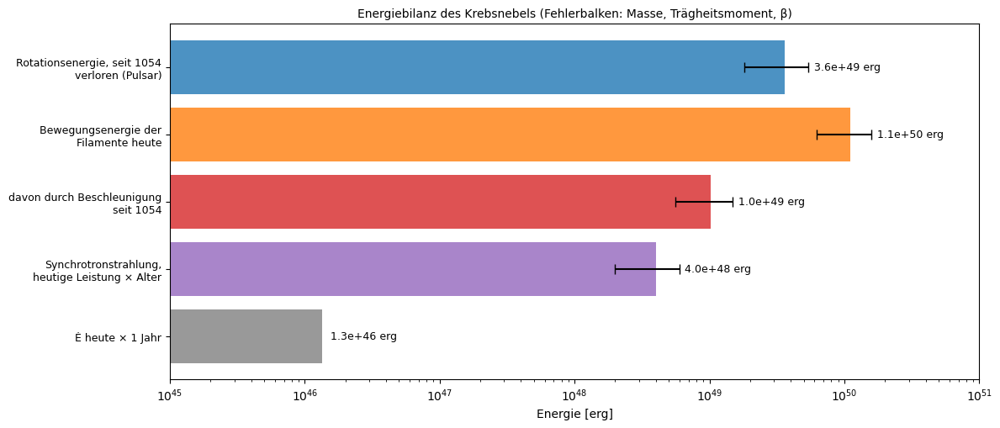

In [71]:
crab.energy()